# EVA-X-Tiny: three frozen pretrained pipelines
**Validation gate:** the official checkpoint smoke test must pass before any real-data experiment. Architecture-only tests pass with timm 0.9.16 / torch 2.5.1 / torchvision 0.20.1. The README-suggested timm 0.9.0 fails the official forward pass (missing `_pos_embed`). The cloud proxy blocks Hugging Face with HTTP 403. Thus official pretrained loading, 192D pretrained features and full experiments are **not locally validated**. No results are prefilled. A successful Colab execution must establish these properties rather than assume them.

Compare DenseNet Lung Opacity + OLS, ResNet18 ImageNet 512D + Ridge, and EVA-X-Tiny CXR 192D + Ridge. No prior notebook or result is modified. Outputs: `/content/duong-eva-x-results/`.


In [9]:
!git clone --branch eva-x-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

fatal: destination path '/content/nus_DSA5206_GROUPPROJECT' already exists and is not an empty directory.


In [10]:
# Colab: run once, restart runtime if requested, then continue below.
%pip install torch==2.5.1 torchvision==0.20.1 torchxrayvision==1.4.0 numpy==1.26.4 pandas==2.2.3 scipy==1.14.1 scikit-learn==1.5.2 scikit-image==0.24.0 matplotlib==3.9.2 timm==0.9.16


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.5/906.5 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 

In [11]:
!git clone --branch eva-x-comparison \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

fatal: destination path '/content/nus_DSA5206_GROUPPROJECT' already exists and is not an empty directory.


In [12]:
%cd /content/nus_DSA5206_GROUPPROJECT

!git fetch origin
!git switch eva-x-comparison
!git pull origin eva-x-comparison

/content/nus_DSA5206_GROUPPROJECT
remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 6 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.86 KiB | 25.00 KiB/s, done.
From https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT
   20a3818..6cab6f1  eva-x-comparison -> origin/eva-x-comparison
Already on 'eva-x-comparison'
Your branch is behind 'origin/eva-x-comparison' by 2 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT
 * branch            eva-x-comparison -> FETCH_HEAD
Updating 20a3818..6cab6f1
Fast-forward
 EVA_X_Comparison.ipynb | 123 ++++++++++++++++++++++++++++++++++---------------
 1 file changed, 87 insertions(+), 36 deletions(-)


In [13]:
import sys
import importlib.util
import importlib.machinery
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT").resolve()

def load_module(name):
    path = repo / f"{name}.py"

    assert path.is_file(), f"File not found: {path}"

    loader = importlib.machinery.SourceFileLoader(
        name, str(path)
    )

    spec = importlib.util.spec_from_loader(
        name, loader
    )

    module = importlib.util.module_from_spec(spec)

    # 注册模块，供其他 Python 文件 import
    sys.modules[name] = module

    try:
        loader.exec_module(module)
    except Exception:
        sys.modules.pop(name, None)
        raise

    print(f"Successfully loaded: {name}")
    return module

# 按依赖顺序加载
critical_methods = load_module("critical_methods")
resnet18_methods = load_module("resnet18_methods")
eva_x_methods = load_module("eva_x_methods")

print("\nAll three modules loaded successfully!")

Successfully loaded: critical_methods
Successfully loaded: resnet18_methods
Successfully loaded: eva_x_methods

All three modules loaded successfully!


In [14]:
import sys
import os
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

# 检查仓库是否存在
print("Repository exists:", repo.is_dir())

# 检查三个必需的模块
modules = [
    "critical_methods.py",
    "resnet18_methods.py",
    "eva_x_methods.py"
]

for name in modules:
    path = repo / name
    print(f"{name}: {path.is_file()}")

# 加入 Python 搜索路径
assert repo.is_dir(), "GitHub repository not found"

for name in modules:
    assert (repo / name).is_file(), f"Missing {name}"

sys.path.insert(0, str(repo.resolve()))
os.chdir(repo)

# 测试导入
import critical_methods
import resnet18_methods
import eva_x_methods

print("\nAll project modules loaded successfully!")

Repository exists: True
critical_methods.py: True
resnet18_methods.py: True
eva_x_methods.py: True

All project modules loaded successfully!


In [1]:
# Optional: mount Drive before configuring historical data.
from google.colab import drive
drive.mount('/content/drive')
import os,sys,json,platform,importlib.metadata,shutil
from pathlib import Path
from time import perf_counter
from urllib.parse import urlparse
REPO_DIR=Path(os.environ.get('DUONG_REPO_DIR','/content/nus_DSA5206_GROUPPROJECT')).resolve()
DATA_DIR=Path(os.environ.get('DUONG_DATA_DIR','/content/drive/MyDrive/duong-data')).resolve()
IMAGE_DIR=Path(os.environ.get('DUONG_IMAGE_DIR',str(DATA_DIR/'images')))
METADATA_CSV=Path(os.environ.get('DUONG_METADATA_CSV',str(DATA_DIR/'metadata_2020.csv')))
SCORES_CSV=Path(os.environ.get('DUONG_SCORES_CSV',str(DATA_DIR/'covid-severity-scores.csv')))
ASSESSMENT_DIR=Path(os.environ.get('DUONG_CRITICAL_RESULTS_DIR','/content/duong-critical-assessment-results'))
REPRO_DIR=Path(os.environ.get('DUONG_REPRO_RESULTS_DIR','/content/duong-improved-results'))
RESNET_RESULTS_DIR=Path(os.environ.get('DUONG_RESNET_RESULTS_DIR','/content/duong-resnet18-results'))
OUTPUT_DIR=Path('/content/duong-eva-x-results/').resolve()
assert OUTPUT_DIR!=REPO_DIR and REPO_DIR not in OUTPUT_DIR.parents
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(REPO_DIR));os.chdir(OUTPUT_DIR)
INCLUDE_PCA=False # three prespecified primary pipelines only
import torch,numpy as np,pandas as pd
from PIL import Image
from threadpoolctl import threadpool_limits
from IPython.display import display
from critical_methods import sha256_file,fingerprint,exact_splits
from resnet18_methods import (BASELINE,RIDGE,ALPHAS,SCATTER_SEED,validate_heldout_records,
    paired_alignment,compare_models,aligned_features)
from eva_x_methods import (official_source,official_checkpoint,pretrained_smoke,pooled_features,
    evaluation_transform,PREPROCESSING,OFFICIAL_COMMIT,EVA_MODEL,evaluate_eva,verify_prior_identity)
torch.set_num_threads(2)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Smoke test first: official model, weights and CXR preprocessing
The pinned official `eva_x.py` factory `eva_x_tiny_patch16` is called unchanged. Its permissive loading is audited: **every non-head backbone tensor must match the filtered checkpoint in key, shape and value**; missing backbone tensors stop execution. Missing random classification-head weights are reported and unused.

Use `forward_head(forward_features(x), pre_logits=True)`: mean of patch tokens excluding prefix tokens, followed by the official `fc_norm`; no classification logits or flattened token sequence. Freeze all parameters, eval mode, inference_mode. Repeat the same synthetic grayscale image and require bitwise-equal finite (1,192) output. Record warnings, checkpoint SHA, device and versions.

Preprocessing follows pinned `classification/utils/datasets.py` **non-CheXpert CXR14 evaluation**: official PIL RGB conversion (grayscale is naturally replicated), bicubic shorter-edge resize 256, center crop 224, tensor [0,1], mean=0.49185243/std=0.28509309 per channel. The official CheXpert-Tiny branch instead resizes to 224 before cropping. There is no uniquely specified COVID severity policy; CXR14 is prespecified here, not selected on test outcomes. No ImageNet normalization is substituted.


In [25]:
import torch

print("Before cleanup:")
print(torch.serialization.get_safe_globals())

# 清除之前添加的错误白名单
torch.serialization.clear_safe_globals()

print("\nAfter cleanup:")
print(torch.serialization.get_safe_globals())

Before cleanup:
[<class 'numpy.dtypes.Float32DType'>, <class 'numpy.dtypes.Int64DType'>, <class 'numpy.dtypes.Float64DType'>, (<built-in function scalar>, 'numpy.core.multiarray.scalar'), <built-in function scalar>, <class 'numpy.dtype'>]

After cleanup:
[]


In [26]:
import numpy as np
import torch

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)

NumPy: 1.26.4
PyTorch: 2.5.1+cu124


In [27]:
%pip install --force-reinstall --no-deps numpy==1.26.4

  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


In [2]:
!git clone --branch error-analysis \
https://github.com/ZIYINGLAN/nus_DSA5206_GROUPPROJECT.git \
/content/nus_DSA5206_GROUPPROJECT

fatal: destination path '/content/nus_DSA5206_GROUPPROJECT' already exists and is not an empty directory.


In [4]:
import sys
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

assert (repo / "eva_x_methods.py").is_file()

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

import eva_x_methods

print("Successfully imported:", eva_x_methods.__file__)

Successfully imported: /content/nus_DSA5206_GROUPPROJECT/eva_x_methods.py


In [7]:
import sys
from pathlib import Path

repo = Path("/content/nus_DSA5206_GROUPPROJECT")

assert (repo / "eva_x_methods.py").is_file(), (
    "eva_x_methods.py not found. Please clone the repository first."
)

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from eva_x_methods import (
    official_source,
    official_checkpoint,
    pretrained_smoke
)

print("EVA-X functions imported successfully!")

EVA-X functions imported successfully!


In [9]:
import os
from pathlib import Path

OUTPUT_DIR = Path("/content/duong-eva-x-results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assets = OUTPUT_DIR / "eva_assets"

source = official_source(assets)

checkpoint, checkpoint_info = official_checkpoint(
    assets,
    os.environ.get("DUONG_EVA_CHECKPOINT"),
    os.environ.get(
        "DUONG_EVA_CHECKPOINT_SHA256",
        "f82d6fc450a83ac7c4d32fa9f0d6459ea7a53fd08e47fdef0cb12ce35c97174d"
    )
)

print("Source:", source)
print("Checkpoint:", checkpoint)

Source: /content/duong-eva-x-results/eva_assets/official_eva_x.py
Checkpoint: /content/duong-eva-x-results/eva_assets/eva_x_tiny_patch16_merged520k_mim.pt


In [11]:
import torch
import eva_x_methods

# 清除之前可能残留的不兼容白名单
torch.serialization.clear_safe_globals()

# 只添加当前 checkpoint 所需的标准 Python 类型
torch.serialization.add_safe_globals([set])

print("PyTorch:", torch.__version__)
print("Safe globals:", torch.serialization.get_safe_globals())

PyTorch: 2.5.1+cu124
Safe globals: [<class 'set'>]


In [12]:
eva, smoke_report = pretrained_smoke(
    source,
    checkpoint,
    checkpoint_info["sha256"]
)

print("Status:", smoke_report["status"])
print("Feature shape:", smoke_report["feature_shape"])
print(
    "Backbone coverage:",
    smoke_report["loading"]["backbone_coverage_fraction"]
)

_IncompatibleKeys(missing_keys=['head.weight', 'head.bias'], unexpected_keys=[])
Status: passed
Feature shape: [1, 192]
Backbone coverage: 1.0


In [15]:
import json

# 保存已经成功生成的 Smoke Test 报告
(OUTPUT_DIR / "eva_smoke_report.json").write_text(
    json.dumps(smoke_report, indent=2)
)

print("Status:", smoke_report["status"])
print("Feature shape:", smoke_report["feature_shape"])
print(
    "Backbone coverage:",
    smoke_report["loading"]["backbone_coverage_fraction"]
)

print("\nSmoke Test report saved successfully!")

Status: passed
Feature shape: [1, 192]
Backbone coverage: 1.0

Smoke Test report saved successfully!


In [16]:
assets=OUTPUT_DIR/'eva_assets'
source=official_source(assets)
local_checkpoint=os.environ.get('DUONG_EVA_CHECKPOINT')
# Expected local-file checksum supplied by the user; not locally verified against weights.
expected_local_sha=os.environ.get('DUONG_EVA_CHECKPOINT_SHA256','f82d6fc450a83ac7c4d32fa9f0d6459ea7a53fd08e47fdef0cb12ce35c97174d')
checkpoint,checkpoint_info=official_checkpoint(assets,local_checkpoint,expected_local_sha)
eva,smoke_report=pretrained_smoke(source,checkpoint,checkpoint_info['sha256'])
assert smoke_report['status']=='passed'
(OUTPUT_DIR/'eva_smoke_report.json').write_text(json.dumps(smoke_report,indent=2))
print(json.dumps(smoke_report,indent=2))


_IncompatibleKeys(missing_keys=['head.weight', 'head.bias'], unexpected_keys=[])
{
  "status": "passed",
  "synthetic_image": true,
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "feature_shape": [
    1,
    192
  ],
  "repeat_bitwise_equal": true,
  "checkpoint_sha256": "f82d6fc450a83ac7c4d32fa9f0d6459ea7a53fd08e47fdef0cb12ce35c97174d",
  "device": "cpu",
  "python": "3.11.13",
  "versions": {
    "torch": "2.5.1",
    "torchvision": "0.20.1",
    "timm": "0.9.16"
  },
  "loading": {
    "backbone_state_tensors": 162,
    "backbone_numel": 5525184,
    "backbone_coverage_fraction": 1.0,
    "ignored_missing_head_keys": [
      "head.weight",
      "head.bias"
    ],
    "warnings": [],
    "pooling": "official forward_head(pre_logits=True): mean patch tokens excluding prefix, fc_norm",
    "deserialization": {
      "weights_only": true,
      "unrestricted_fallback": false,
      "sha256_verified_before_deserialization": true,
      "safe_globals": [
        "numpy.core.mu

## Reuse the exact validated data and earlier baseline workflow
To avoid a second loader implementation, execute the unchanged existing ResNet notebook's data cell and feature/baseline cells in a dedicated namespace, with OUTPUT_DIR redirected to this new comparison's `baseline_revalidation/`. The old notebook is **read**, never saved or changed. Execution uses the old loader, join/mask, ordered manifests, patient IDs, exact_splits, hash tracking and baseline provenance rules.

When previous ResNet source manifests are available, stop on differences in source CSVs, images, ordered names, patient IDs or targets before doing inference. Copy earlier feature cache into the new working directory only as a read-only source; the original workflow itself verifies its fingerprint/checksum and regenerates when needed. Re-run inexpensive baseline fitting for numerical verification. Historical predictions are reused only after data/weight/feature/preprocessing/environment/split checks **and** agreement with recomputed per-image predictions. Summary means alone never supply predictions.


In [17]:
%pip install torchxrayvision==1.4.0

In [35]:
INCLUDE_PCA = False

In [36]:
import os
import sys
import json
import shutil
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from time import perf_counter
from urllib.parse import urlparse
from threadpoolctl import threadpool_limits
from PIL import Image

from critical_methods import (
    sha256_file,
    fingerprint,
    exact_splits
)

from resnet18_methods import (
    BASELINE,
    RIDGE,
    ALPHAS,
    SCATTER_SEED,
    validate_heldout_records,
    paired_alignment,
    compare_models,
    aligned_features
)

from eva_x_methods import (
    official_source,
    official_checkpoint,
    pretrained_smoke,
    pooled_features,
    evaluation_transform,
    PREPROCESSING,
    OFFICIAL_COMMIT,
    EVA_MODEL,
    evaluate_eva,
    verify_prior_identity
)

# 与原始 EVA-X Notebook 保持一致
INCLUDE_PCA = False

print("All EVA-X configuration imports restored.")
print("INCLUDE_PCA:", INCLUDE_PCA)

All EVA-X configuration imports restored.
INCLUDE_PCA: False


In [20]:
import os
import sys
import json
from pathlib import Path

# GitHub 仓库
REPO_DIR = Path(
    "/content/nus_DSA5206_GROUPPROJECT"
).resolve()

# Google Drive 中的原始数据
DATA_DIR = Path(
    "/content/drive/MyDrive/duong-data"
).resolve()

IMAGE_DIR = DATA_DIR / "images"
METADATA_CSV = DATA_DIR / "metadata_2020.csv"
SCORES_CSV = DATA_DIR / "covid-severity-scores.csv"

# 之前实验的结果目录
ASSESSMENT_DIR = Path(
    "/content/duong-critical-assessment-results"
)

REPRO_DIR = Path(
    "/content/duong-improved-results"
)

RESNET_RESULTS_DIR = Path(
    "/content/duong-resnet18-results"
)

# 保留当前已经成功运行的 EVA-X 输出目录
if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = Path("/content/duong-eva-x-results")

# 验证路径
paths = {
    "GitHub Repository": REPO_DIR,
    "Chest X-ray Images": IMAGE_DIR,
    "Historical Metadata": METADATA_CSV,
    "Severity Scores": SCORES_CSV,
}

for name, path in paths.items():
    print(f"{name}: {path.exists()}")

assert REPO_DIR.is_dir()
assert IMAGE_DIR.is_dir()
assert METADATA_CSV.is_file()
assert SCORES_CSV.is_file()

print("\nAll required paths verified!")

GitHub Repository: True
Chest X-ray Images: True
Historical Metadata: True
Severity Scores: True

All required paths verified!


In [22]:
required_vars = [
    "REPO_DIR",
    "DATA_DIR",
    "IMAGE_DIR",
    "METADATA_CSV",
    "SCORES_CSV",
    "ASSESSMENT_DIR",
    "REPRO_DIR",
    "RESNET_RESULTS_DIR",
    "OUTPUT_DIR",
    "eva",
    "smoke_report",
    "json",
]

for name in required_vars:
    print(
        f"{name:22s}",
        "✓" if name in globals() else "MISSING"
    )

REPO_DIR               ✓
DATA_DIR               ✓
IMAGE_DIR              ✓
METADATA_CSV           ✓
SCORES_CSV             ✓
ASSESSMENT_DIR         ✓
REPRO_DIR              ✓
RESNET_RESULTS_DIR     ✓
OUTPUT_DIR             ✓
eva                    ✓
smoke_report           ✓
json                   ✓


In [26]:
import sys
from pathlib import Path

REPO_DIR = Path("/content/nus_DSA5206_GROUPPROJECT")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from critical_methods import sha256_file, fingerprint, exact_splits

print("SHA-256 function imported successfully!")

SHA-256 function imported successfully!


In [28]:
from time import perf_counter

# 确保 exec 使用的命名空间也有这个函数
baseline_ns["perf_counter"] = perf_counter

print("perf_counter imported successfully")
print("Available in baseline_ns:", "perf_counter" in baseline_ns)

perf_counter imported successfully
Available in baseline_ns: True


In [31]:
from urllib.parse import urlparse

# 将函数添加到基线实验使用的命名空间
baseline_ns["urlparse"] = urlparse

print("urlparse available:", "urlparse" in baseline_ns)

urlparse available: True


In [37]:
assert smoke_report['status']=='passed', 'Do not bypass the pretrained compatibility gate'
assert IMAGE_DIR.is_dir() and METADATA_CSV.is_file() and SCORES_CSV.is_file()
prior_notebook_path=REPO_DIR/'ResNet18_Comparison.ipynb'
prior_notebook=json.loads(prior_notebook_path.read_text())
# The selected cells are located by their reviewed entry points, not cell numbers.
def prior_cell(prefix):
    matches=[''.join(c['source']) for c in prior_notebook['cells']
             if c['cell_type']=='code' and ''.join(c['source']).startswith(prefix)]
    assert len(matches)==1, 'Prior notebook structure changed: review before proceeding'
    return matches[0]
work=OUTPUT_DIR/'baseline_revalidation';work.mkdir(exist_ok=True)
baseline_ns=dict(globals());baseline_ns['OUTPUT_DIR']=work
# Identical data loading, score join/mask, historical split/identity audit.
exec(prior_cell('import numpy as np,pandas as pd,torch,torchvision,torchxrayvision as xrv'),baseline_ns)
metadata=baseline_ns['metadata']
assert len(metadata)==94 and metadata.patientid.nunique()==65
current_identity={
 'ordered_filenames':metadata.filename.tolist(),'ordered_patient_ids':metadata.patientid.tolist(),
 'ordered_labels':metadata[['geographic_mean','opacity_mean']].to_dict(orient='list'),
 'metadata_sha256':sha256_file(METADATA_CSV),'scores_sha256':sha256_file(SCORES_CSV),
 'scored_image_sha256':{f:sha256_file(IMAGE_DIR/f) for f in metadata.filename}}
prior_manifest_path=RESNET_RESULTS_DIR/'reproducibility_manifest.json'
previous=json.loads(prior_manifest_path.read_text()) if prior_manifest_path.is_file() else None
if previous is not None:verify_prior_identity(previous,current_identity)
# Reuse separate old feature caches only through the old validation logic.
for name in ['frozen_features.npz','frozen_features_manifest.json']:
    source_cache=RESNET_RESULTS_DIR/name
    if source_cache.is_file() and not (work/name).exists():shutil.copyfile(source_cache,work/name)
exec(prior_cell("torch.hub.set_dir(str(OUTPUT_DIR/'torch-cache'))"),baseline_ns)
exec(prior_cell('start=perf_counter()\nwith threadpool_limits(limits=2):\n    regenerated=generate_baseline'),baseline_ns)


unavailable: no historical heldout_predictions.csv; regenerated records will be audited
Verified shapes: (94, 512) (94, 18) cache reused: False
regenerated DenseNet + OLS


In [38]:
# Recompute earlier Ridge with exactly the existing code. This also revalidates
# any historical per-seed predictions numerically rather than trusting a CSV alone.
start=perf_counter()
with threadpool_limits(limits=2):
    prior_metrics,regenerated_predictions,prior_timing,prior_inner=compare_models(
        baseline_ns['resnet_features'],metadata,baseline_ns['baseline'],include_pca=False)
baseline_seconds=perf_counter()-start
earlier=regenerated_predictions
baseline_source='regenerated with validated ResNet/DenseNet code (verified feature cache if compatible)'
old_predictions_path=RESNET_RESULTS_DIR/'all_model_heldout_predictions.csv'
if old_predictions_path.is_file():
    old=pd.read_csv(old_predictions_path,dtype={'patientid':metadata.patientid.dtype})
    old=old[old.model.isin([BASELINE,RIDGE])].copy()
    for name in [BASELINE,RIDGE]:validate_heldout_records(old,metadata,'model',name)
    paired_alignment(old)
    now=baseline_ns['manifest']
    provenance_keys=['resnet_weights','resnet_checkpoint_sha256','resnet_preprocessing','grayscale_policy',
       'checkpoint_sha256','pathologies','packages','outer_split_config','inner_cv','inner_score',
       'ridge_alphas','standardization','ridge_solver','helper_sha256','critical_methods_sha256']
    provenance_match=previous is not None and all(previous.get(k)==now.get(k) for k in provenance_keys)
    if provenance_match:
        keys=['model','target','seed','row_index']
        joined=old.merge(regenerated_predictions,on=keys,validate='one_to_one',suffixes=('_cache','_new'))
        assert len(joined)==len(old)==len(regenerated_predictions)
        np.testing.assert_allclose(joined.y_pred_cache,joined.y_pred_new,rtol=1e-5,atol=1e-5)
        earlier=old
        baseline_source='historical CSV, identity/provenance/splits and numerical predictions revalidated'
    else:print('Earlier feature/model provenance incomplete or different; regenerated baselines used')
print(baseline_source)
earlier.to_csv(OUTPUT_DIR/'verified_earlier_predictions.csv',index=False)


regenerated with validated ResNet/DenseNet code (verified feature cache if compatible)


## Dedicated EVA feature cache
Never use the ResNet cache for EVA. The integrity manifest includes ordered filenames/patient IDs/labels, input image and annotation hashes, checkpoint and source hashes, exact transform, pooling, dependency versions and helper hashes. Fingerprint or payload checksum mismatch regenerates EVA features. File names alone are insufficient. No gradients or backbone training are enabled.


In [39]:
versions={p:importlib.metadata.version(p) for p in ['torch','torchvision','timm','numpy','pandas','scipy','scikit-learn','scikit-image','matplotlib','torchxrayvision']}
manifest={**current_identity,'packages':versions,'python':platform.python_version(),
 'eva_source_commit':OFFICIAL_COMMIT,'eva_source_sha256':sha256_file(source),
 'eva_checkpoint':checkpoint_info,'preprocessing':PREPROCESSING,'pooling':smoke_report['loading']['pooling'],
 'feature_dimension':192,'backbone_frozen':True,'device':'cpu','outer_seeds':list(range(50)),
 'outer_splits':'critical_methods.exact_splits','inner_cv':baseline_ns['manifest']['inner_cv'],
 'ridge_alphas':list(ALPHAS),'inner_score':'negative MSE','scaler':'fold-local StandardScaler',
 'baseline_source':baseline_source,'baseline_manifest':baseline_ns['manifest'],
 'previous_predictions_sha256':sha256_file(old_predictions_path) if old_predictions_path.is_file() else None,
 'shared_notebook_sha256':sha256_file(prior_notebook_path),
 'eva_helper_sha256':sha256_file(REPO_DIR/'eva_x_methods.py'),
 'resnet_helper_sha256':sha256_file(REPO_DIR/'resnet18_methods.py'),
 'critical_helper_sha256':sha256_file(REPO_DIR/'critical_methods.py'),'scatter_seed':SCATTER_SEED}
cache_fingerprint=fingerprint(manifest)
cache=OUTPUT_DIR/'eva_x_features.npz';integrity_path=OUTPUT_DIR/'feature_integrity_manifest.json'
reused=False;extract_seconds=None
if cache.is_file() and integrity_path.is_file():
    integrity=json.loads(integrity_path.read_text())
    if integrity.get('fingerprint')==cache_fingerprint and integrity.get('payload_sha256')==sha256_file(cache):
        with np.load(cache,allow_pickle=False) as payload:eva_features=payload['features'].copy()
        reused=True
if not reused:
    tensors=[];start=perf_counter();transform=evaluation_transform()
    for offset in range(0,len(metadata),8):
        batch=[]
        for name in metadata.filename.iloc[offset:offset+8]:
            with Image.open(IMAGE_DIR/name) as image:batch.append(transform(image.convert('RGB')))
        tensors.append(pooled_features(eva,torch.stack(batch)).cpu().numpy())
    eva_features=np.concatenate(tensors);extract_seconds=perf_counter()-start
aligned_features(eva_features,metadata.filename,metadata,192)
assert eva_features.shape==(94,192)
np.savez(cache,features=eva_features)
integrity_path.write_text(json.dumps({'fingerprint':cache_fingerprint,'payload_sha256':sha256_file(cache),
 'feature_provenance':manifest},indent=2))
metadata.to_csv(OUTPUT_DIR/'ordered_sample_manifest.csv',index=False)
print('Feature cache hit:',reused,'shape:',eva_features.shape)


Feature cache hit: False shape: (94, 192)


In [40]:
start=perf_counter()
with threadpool_limits(limits=2):
    by_seed,predictions,timings,audit=evaluate_eva(eva_features,metadata,earlier)
evaluation_seconds=perf_counter()-start
assert len(by_seed)==300 and len(audit)==50
by_seed.to_csv(OUTPUT_DIR/'three_model_comparison_by_seed.csv',index=False)
summary=by_seed.groupby(['target','model'])[['MAE','MSE','R2','Pearson']].agg(['mean','std','count'])
summary.to_csv(OUTPUT_DIR/'three_model_comparison_summary.csv');display(summary)
formatted=pd.DataFrame(index=summary.index)
for metric in ['MAE','MSE','R2','Pearson']:
    formatted[metric]=[f'{mean:.3f} ± {std:.3f}' if np.isfinite(mean) else 'N/A'
        for mean,std in zip(summary[(metric,'mean')],summary[(metric,'std')])]
display(formatted)
predictions[predictions.model==EVA_MODEL].to_csv(OUTPUT_DIR/'eva_x_heldout_predictions.csv',index=False)
predictions.to_csv(OUTPUT_DIR/'three_model_heldout_predictions.csv',index=False)
paired=by_seed.pivot(index=['target','seed'],columns='model',values='MAE')
paired['EVA-X minus DenseNet']=paired[EVA_MODEL]-paired[BASELINE]
paired['EVA-X minus ResNet18']=paired[EVA_MODEL]-paired[RIDGE]
paired[['EVA-X minus DenseNet','EVA-X minus ResNet18']].to_csv(OUTPUT_DIR/'paired_eva_x_differences.csv')
(OUTPUT_DIR/'patient_split_audit.json').write_text(json.dumps(audit,indent=2,default=lambda v:v.item()))
(OUTPUT_DIR/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2))
timings.to_csv(OUTPUT_DIR/'eva_regression_timing.csv',index=False)
(OUTPUT_DIR/'runtime_measurements.json').write_text(json.dumps({'eva_feature_cache_hit':reused,
 'eva_extract_seconds_including_decode_preprocess':extract_seconds,
 'earlier_baseline_search_seconds':baseline_seconds,'eva_evaluation_seconds':evaluation_seconds,
 'earlier_pipeline_resources':baseline_ns['resources']},indent=2))
# User-provided historical means: diagnostics only, never a source of predictions.
reference={('Geographic Extent',BASELINE):(1.160550,.604102),('Geographic Extent',RIDGE):(1.545298,.316714),
 ('Opacity',BASELINE):(.787543,.592061),('Opacity',RIDGE):(.981873,.288485)}
reference_checks=[]
for key,(mae,r2) in reference.items():
    reference_checks.append({'target':key[0],'model':key[1],
        'observed_mean_MAE':summary.loc[key,('MAE','mean')],'reference_mean_MAE':mae,
        'observed_mean_R2':summary.loc[key,('R2','mean')],'reference_mean_R2':r2})
display(pd.DataFrame(reference_checks))
print('Reference deviations require explanation, never changes to seeds or test-tuned settings.')


MAE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  1.160550  0.102216    50   
                  EVA-X-Tiny + Ridge           0.984245  0.125442    50   
                  ResNet18 + Ridge             1.545298  0.184982    50   
Opacity           DenseNet Lung Opacity + OLS  0.787543  0.060755    50   
                  EVA-X-Tiny + Ridge           0.709722  0.072222    50   
                  ResNet18 + Ridge             0.981873  0.115360    50   

                                                    MSE                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  2.145127  0.330163    50   
                  EVA-X-Tiny + Ridge           1.574649  0.446612    50   
                  ResNet18 + Ridge             3.763158  0.784417    50   
Opacity           DenseNet Lung Opacity + OLS  0.891600  0.123510    50   
                  EVA-X-Tiny + Ridge           0.791363  0.163287    50   
                  ResNet18 + Ridge             1.577103  0.371064    50   

                                                     R2                  \
                                                   mean       std count   
target            model                                                   
Geographic Extent DenseNet Lung Opacity + OLS  0.604102  0.077206    50   
                  EVA-X-Tiny + Ridge           0.713206  0.071696    50   
                  ResNet18 + Ridge             0.316714  0.103456    50   
Opacity           DenseNet Lung Opacity + OLS  0.592061  0.065382    50   
                  EVA-X-Tiny + Ridge           0.638887  0.075630    50   
                  ResNet18 + Ridge             0.288485  0.134218    50   

                                                Pearson                  
                                                   mean       std count  
target            model                                                  
Geographic Extent DenseNet Lung Opacity + OLS  0.807819  0.036237    50  
                  EVA-X-Tiny + Ridge           0.861477  0.039433    50  
                  ResNet18 + Ridge             0.633787  0.086600    50  
Opacity           DenseNet Lung Opacity + OLS  0.792832  0.040076    50  
                  EVA-X-Tiny + Ridge           0.821998  0.040499    50  
                  ResNet18 + Ridge             0.613558  0.097666    50

MAE            MSE  \
target            model                                                       
Geographic Extent DenseNet Lung Opacity + OLS  1.161 ± 0.102  2.145 ± 0.330   
                  EVA-X-Tiny + Ridge           0.984 ± 0.125  1.575 ± 0.447   
                  ResNet18 + Ridge             1.545 ± 0.185  3.763 ± 0.784   
Opacity           DenseNet Lung Opacity + OLS  0.788 ± 0.061  0.892 ± 0.124   
                  EVA-X-Tiny + Ridge           0.710 ± 0.072  0.791 ± 0.163   
                  ResNet18 + Ridge             0.982 ± 0.115  1.577 ± 0.371   

                                                          R2        Pearson  
target            model                                                      
Geographic Extent DenseNet Lung Opacity + OLS  0.604 ± 0.077  0.808 ± 0.036  
                  EVA-X-Tiny + Ridge           0.713 ± 0.072  0.861 ± 0.039  
                  ResNet18 + Ridge             0.317 ± 0.103  0.634 ± 0.087  
Opacity           DenseNet Lung Opacity + OLS  0.592 ± 0.065  0.793 ± 0.040  
                  EVA-X-Tiny + Ridge           0.639 ± 0.076  0.822 ± 0.040  
                  ResNet18 + Ridge             0.288 ± 0.134  0.614 ± 0.098

,target,model,observed_mean_MAE,reference_mean_MAE,observed_mean_R2,reference_mean_R2
0,Geographic Extent,DenseNet Lung Opacity + OLS,1.160550,1.160550,0.604102,0.604102
1,Geographic Extent,ResNet18 + Ridge,1.545298,1.545298,0.316714,0.316714
2,Opacity,DenseNet Lung Opacity + OLS,0.787543,0.787543,0.592061,0.592061
3,Opacity,ResNet18 + Ridge,0.981873,0.981873,0.288485,0.288485


Reference deviations require explanation, never changes to seeds or test-tuned settings.


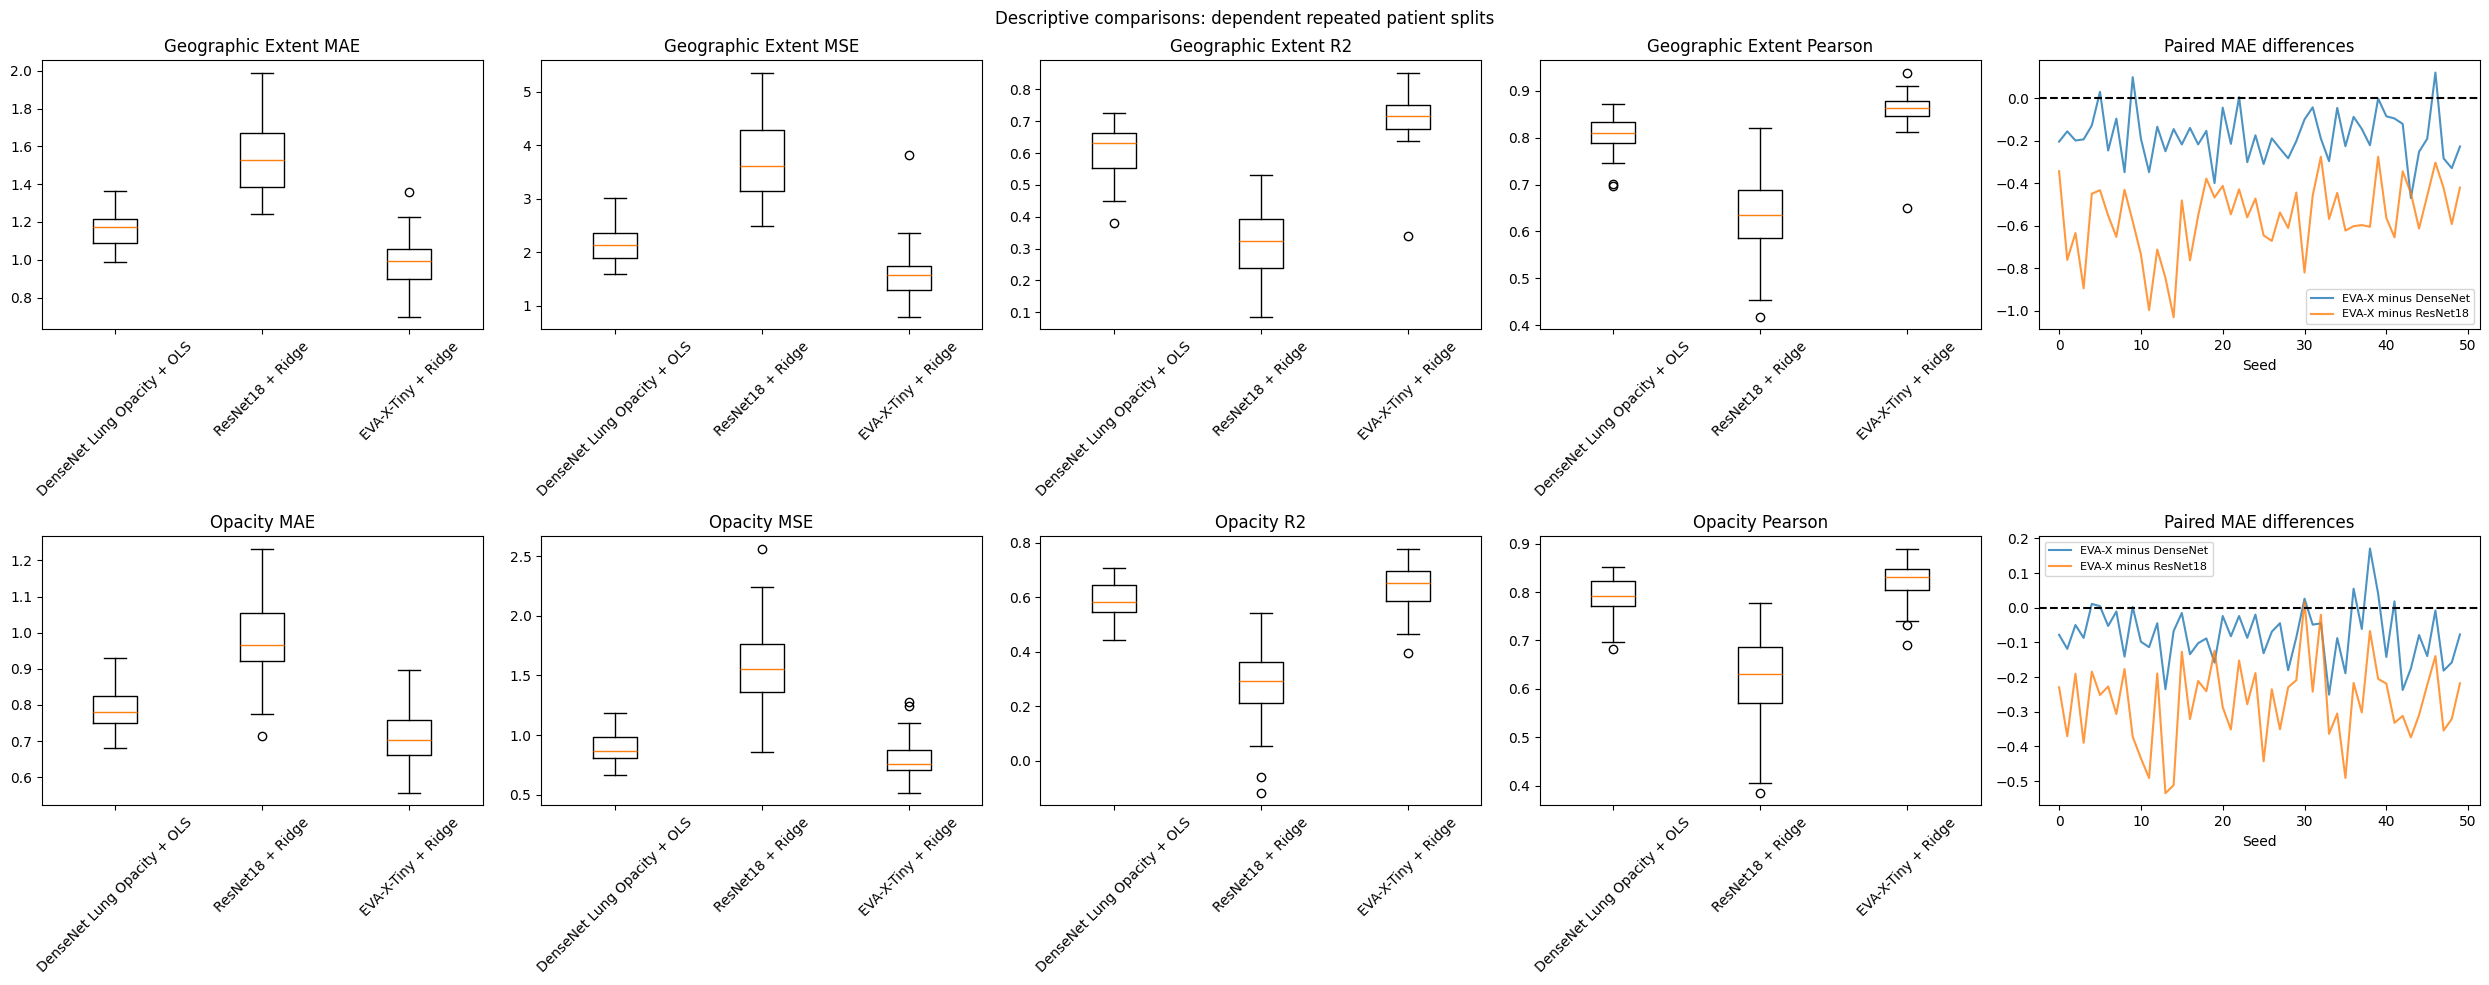

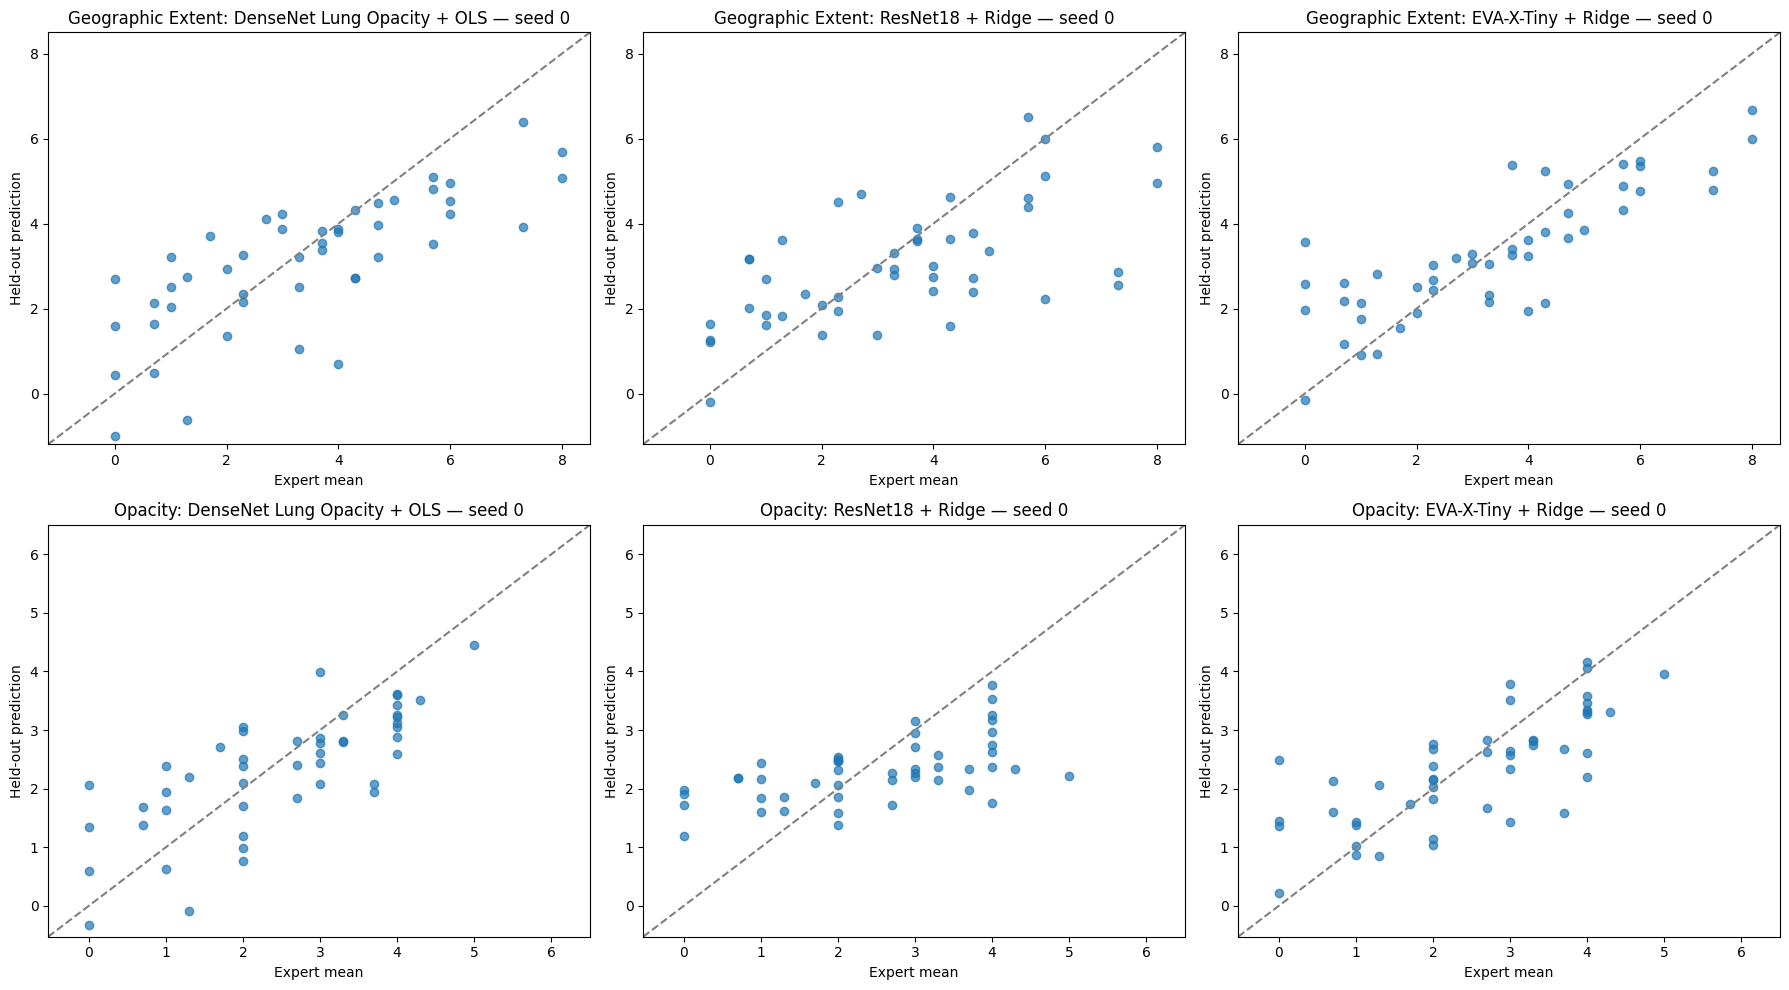

In [41]:
import matplotlib.pyplot as plt
models=[BASELINE,RIDGE,EVA_MODEL]
fig,axes=plt.subplots(2,5,figsize=(25,10))
for i,target in enumerate(['Geographic Extent','Opacity']):
    part=by_seed[by_seed.target==target]
    for j,metric in enumerate(['MAE','MSE','R2','Pearson']):
        axes[i,j].boxplot([part[part.model==m][metric].dropna() for m in models],labels=models)
        axes[i,j].tick_params(axis='x',rotation=45);axes[i,j].set_title(target+' '+metric)
    diff=paired.loc[target]
    for column in ['EVA-X minus DenseNet','EVA-X minus ResNet18']:
        axes[i,4].plot(diff.index,diff[column],label=column,alpha=.8)
    axes[i,4].axhline(0,linestyle='--',color='black');axes[i,4].set_title('Paired MAE differences')
    axes[i,4].set_xlabel('Seed');axes[i,4].legend(fontsize=8)
fig.suptitle('Descriptive comparisons: dependent repeated patient splits')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'three_model_comparison.png',dpi=180);plt.show()
fig,axes=plt.subplots(2,3,figsize=(18,10))
for i,(target,score_max) in enumerate([('Geographic Extent',8),('Opacity',6)]):
    p=predictions[(predictions.target==target)&(predictions.seed==SCATTER_SEED)]
    lo=min(-.5,float(p.y_pred.min())-.2);hi=max(score_max+.5,float(p.y_pred.max())+.2)
    for j,model in enumerate(models):
        q=p[p.model==model];axes[i,j].scatter(q.y_true,q.y_pred,alpha=.7)
        axes[i,j].plot([lo,hi],[lo,hi],'--',color='gray')
        axes[i,j].set(xlim=(lo,hi),ylim=(lo,hi),xlabel='Expert mean',ylabel='Held-out prediction',
                      title=f'{target}: {model} — seed {SCATTER_SEED}')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'eva_x_prediction_scatter.png',dpi=180);plt.show()


In [42]:
from pathlib import Path
import shutil

src = Path("/content/duong-eva-x-results")
dst = Path("/content/drive/MyDrive/duong-eva-x-results")

dst.mkdir(parents=True, exist_ok=True)

required = [
    "three_model_heldout_predictions.csv",
    "patient_split_audit.json",
    "reproducibility_manifest.json"
]

for name in required:
    assert (src / name).is_file(), f"Missing: {name}"
    shutil.copy2(src / name, dst / name)
    print("Saved:", name)

print("All files backed up successfully!")

Saved: three_model_heldout_predictions.csv
Saved: patient_split_audit.json
Saved: reproducibility_manifest.json
All files backed up successfully!


## Interpretation boundaries
This is a comparison of **complete frozen pretrained pipelines**, not architecture alone. EVA-X and DenseNet have CXR pretraining; ResNet18 uses ImageNet. Input preprocessing, pretraining objectives/populations, 192D versus 512D representations and single-logit versus regularized multivariate regression differ simultaneously. A new internal-performance difference would not isolate any one cause.

Only 65 labelled patients (94 images) support inference. Frozen transfer reduces supervised parameters but does not guarantee robustness. Expert score uncertainty and repeated patient observations limit precision. The 50 patient splits overlap and are dependent; report sample SD and descriptive paired differences, not naive independent-replication significance tests. Negative EVA-X minus baseline MAE favours EVA-X descriptively only. No test-set-directed alpha, crop, pooling or seed tuning is allowed.

**Potential pretraining overlap:** neither repository provenance nor new hashes establish disjointness between the Merged520k pretraining images, the CXR-pretrained DenseNet sources and this historical COVID cohort. Absence of patient overlap across our supervised train/test partitions does not eliminate upstream pretraining overlap. This remains unverified and requires upstream source manifests/deduplication. No external validation, clinical readiness or causal interpretation is established.

**Status:** the checkpoint smoke report must say passed in the current run before these experiments execute. Local cloud checkpoint access was blocked, so full pretrained compatibility and real-data results are unexecuted. No historical summary values are used to populate experiment outputs. Cache hits are reported and do not masquerade as fresh extraction timings.


In [43]:
import pandas as pd

path = "/content/drive/MyDrive/duong-data/metadata_2020.csv"
df = pd.read_csv(path)

print(df.columns.tolist())

# 查看许可类型分布
if "license" in df.columns:
    print(df["license"].fillna("UNKNOWN").value_counts())
else:
    print("License column not found; inspect source metadata.")

['patientid', 'offset', 'sex', 'age', 'finding', 'survival', 'intubated', 'intubation_present', 'went_icu', 'needed_supplemental_O2', 'extubated', 'temperature', 'pO2_saturation', 'leukocyte_count', 'neutrophil_count', 'lymphocyte_count', 'view', 'modality', 'date', 'location', 'folder', 'filename', 'doi', 'url', 'license', 'clinical_notes', 'other_notes', 'Unnamed: 27']
license
UNKNOWN                              163
CC BY-NC-SA                          140
CC BY-NC-SA 4.0                       23
CC BY-NC-ND                           14
Apache 2.0                            10
listed as authorized for everyone      7
CC BY                                  2
CC BY-SA                               1
Name: count, dtype: int64


In [44]:
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive")

metadata = pd.read_csv(
    base / "duong-data/metadata_2020.csv"
)

predictions = pd.read_csv(
    base / "duong-eva-x-results/three_model_heldout_predictions.csv"
)

# 提取实验实际使用的唯一影像
images = predictions[
    ["row_index", "filename", "patientid"]
].drop_duplicates().copy()

assert len(images) == 94, f"Expected 94 images, got {len(images)}"

# 标准化用于匹配的文件名
images["match_filename"] = (
    images["filename"].astype(str).str.strip()
)

metadata["match_filename"] = (
    metadata["filename"].astype(str).str.strip()
)

# 检查元数据中是否有重复文件名
duplicates = metadata[
    metadata.duplicated("match_filename", keep=False)
]

print("Experiment images:", len(images))
print("Duplicate metadata rows:", len(duplicates))

# 每个文件名必须对应唯一、无冲突的许可信息
license_info = metadata[
    ["match_filename", "license", "url", "doi"]
].copy()

license_info["license"] = (
    license_info["license"].fillna("UNKNOWN")
    .astype(str).str.strip()
    .replace("", "UNKNOWN")
)

license_info = license_info.drop_duplicates()

license_conflicts = (
    license_info.groupby("match_filename")["license"]
    .nunique()
)

conflicting_names = set(
    license_conflicts[license_conflicts > 1].index
)

# 一张影像一行：汇总重复元数据中的许可
license_summary = (
    license_info.groupby("match_filename", as_index=False)
    .agg(
        license=("license", lambda x: " | ".join(sorted(set(x)))),
        url=("url", "first"),
        doi=("doi", "first"),
    )
)

matched = images.merge(
    license_summary,
    on="match_filename",
    how="left",
    validate="many_to_one",
    indicator=True
)

matched["license"] = matched["license"].fillna("UNKNOWN")
matched["requires_review"] = (
    matched["license"].eq("UNKNOWN")
    | matched["license"].str.contains(
        "authorized for everyone", case=False, na=False
    )
    | matched["match_filename"].isin(conflicting_names)
)

print("\n=== MATCHING SUMMARY ===")
print("Total experiment images:", len(matched))
print("Matched metadata:", (matched["_merge"] == "both").sum())
print("Unmatched images:", (matched["_merge"] != "both").sum())
print("Images requiring review:", matched["requires_review"].sum())

print("\n=== LICENSE DISTRIBUTION FOR 94 IMAGES ===")
print(matched["license"].value_counts().to_string())

print("\n=== REVIEW REASONS ===")
print("Conflicting license entries:",
      matched["match_filename"].isin(conflicting_names).sum())

# 保存完整审计结果到私人 Google Drive
output = base / "duong-data/94_image_license_audit.csv"
matched.to_csv(output, index=False)

print("\nPrivate audit saved:", output)

Experiment images: 94
Duplicate metadata rows: 0

=== MATCHING SUMMARY ===
Total experiment images: 94
Matched metadata: 94
Unmatched images: 0
Images requiring review: 66

=== LICENSE DISTRIBUTION FOR 94 IMAGES ===
license
UNKNOWN        66
CC BY-NC-SA    22
CC BY-NC-ND     6

=== REVIEW REASONS ===
Conflicting license entries: 0

Private audit saved: /content/drive/MyDrive/duong-data/94_image_license_audit.csv


In [45]:
import pandas as pd

audit = pd.read_csv(
    "/content/drive/MyDrive/duong-data/94_image_license_audit.csv"
)

unknown = audit[audit["license"] == "UNKNOWN"].copy()

print("UNKNOWN images:", len(unknown))
print("With source URL:", unknown["url"].notna().sum())
print("With DOI:", unknown["doi"].notna().sum())

print("\nSample source information:")
display(unknown[["url", "doi"]].head(10))

UNKNOWN images: 66
With source URL: 66
With DOI: 30

Sample source information:


,url,doi
0,https://www.thelancet.com/journals/lancet/arti...,10.1016/S0140-6736(20)30211-7
1,https://www.thelancet.com/journals/lancet/arti...,10.1016/S0140-6736(20)30211-7
2,https://pubs.rsna.org/doi/10.1148/radiol.20202...,10.1148/radiol.2020200269
3,https://pubs.rsna.org/doi/full/10.1148/ryct.20...,10.1148/ryct.2020200034
4,https://pubs.rsna.org/doi/full/10.1148/ryct.20...,10.1148/ryct.2020200034
5,https://pubs.rsna.org/doi/full/10.1148/ryct.20...,10.1148/ryct.2020200034
9,https://www.sirm.org/2020/03/03/covid19-caso-2/,NaN
10,https://www.sirm.org/2020/03/08/covid-19-caso-14/,NaN
11,https://www.sirm.org/2020/03/10/covid-19-caso-23/,NaN
12,https://www.sirm.org/2020/03/10/covid-19-caso-27/,NaN


In [47]:
from pathlib import Path
import zipfile

# 优先使用已经保存的 Google Drive 备份
candidates = [
    Path("/content/drive/MyDrive/duong-eva-x-results"),
    Path("/content/duong-eva-x-results"),
]

source = None

for folder in candidates:
    if (
        folder.is_dir()
        and (folder / "three_model_heldout_predictions.csv").is_file()
    ):
        source = folder
        break

assert source is not None, "找不到完整的 EVA-X 三模型实验结果"

zip_path = Path("/content/duong-eva-x-results-download.zip")

# 打包 CSV、JSON 和 PNG，排除大型权重及缓存
with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for file in source.rglob("*"):
        if (
            file.is_file()
            and file.suffix.lower() in {".csv", ".json", ".png"}
            and "private_audit" not in file.parts
        ):
            z.write(
                file,
                arcname=str(file.relative_to(source))
            )
            print("Added:", file.relative_to(source))

print("\nZIP created:", zip_path)
print("Size:", round(zip_path.stat().st_size / 1024**2, 2), "MB")

Added: patient_split_audit.json
Added: three_model_heldout_predictions.csv
Added: reproducibility_manifest.json

ZIP created: /content/duong-eva-x-results-download.zip
Size: 0.24 MB


In [48]:
from google.colab import files

files.download("/content/duong-eva-x-results-download.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EVA feature shape: (94, 192)
Label table shape: (94, 5)
   row_index                                           filename  patientid  \
0          0  auntminnie-a-2020_01_28_23_51_6665_2020_01_28_...          2   
1          1  auntminnie-b-2020_01_28_23_51_6665_2020_01_28_...          2   
2          2  auntminnie-c-2020_01_28_23_51_6665_2020_01_28_...          2   
3          3  auntminnie-d-2020_01_28_23_51_6665_2020_01_28_...          2   
4          4                              nejmc2001573_f1a.jpeg          4   

   geographic_extent  opacity  
0                2.3      1.3  
1                4.0      3.0  
2                4.7      3.0  
3                5.7      3.7  
4                2.0      2.0  
Saved coordinates to: /content/EVA_X_tSNE_coordinates.csv


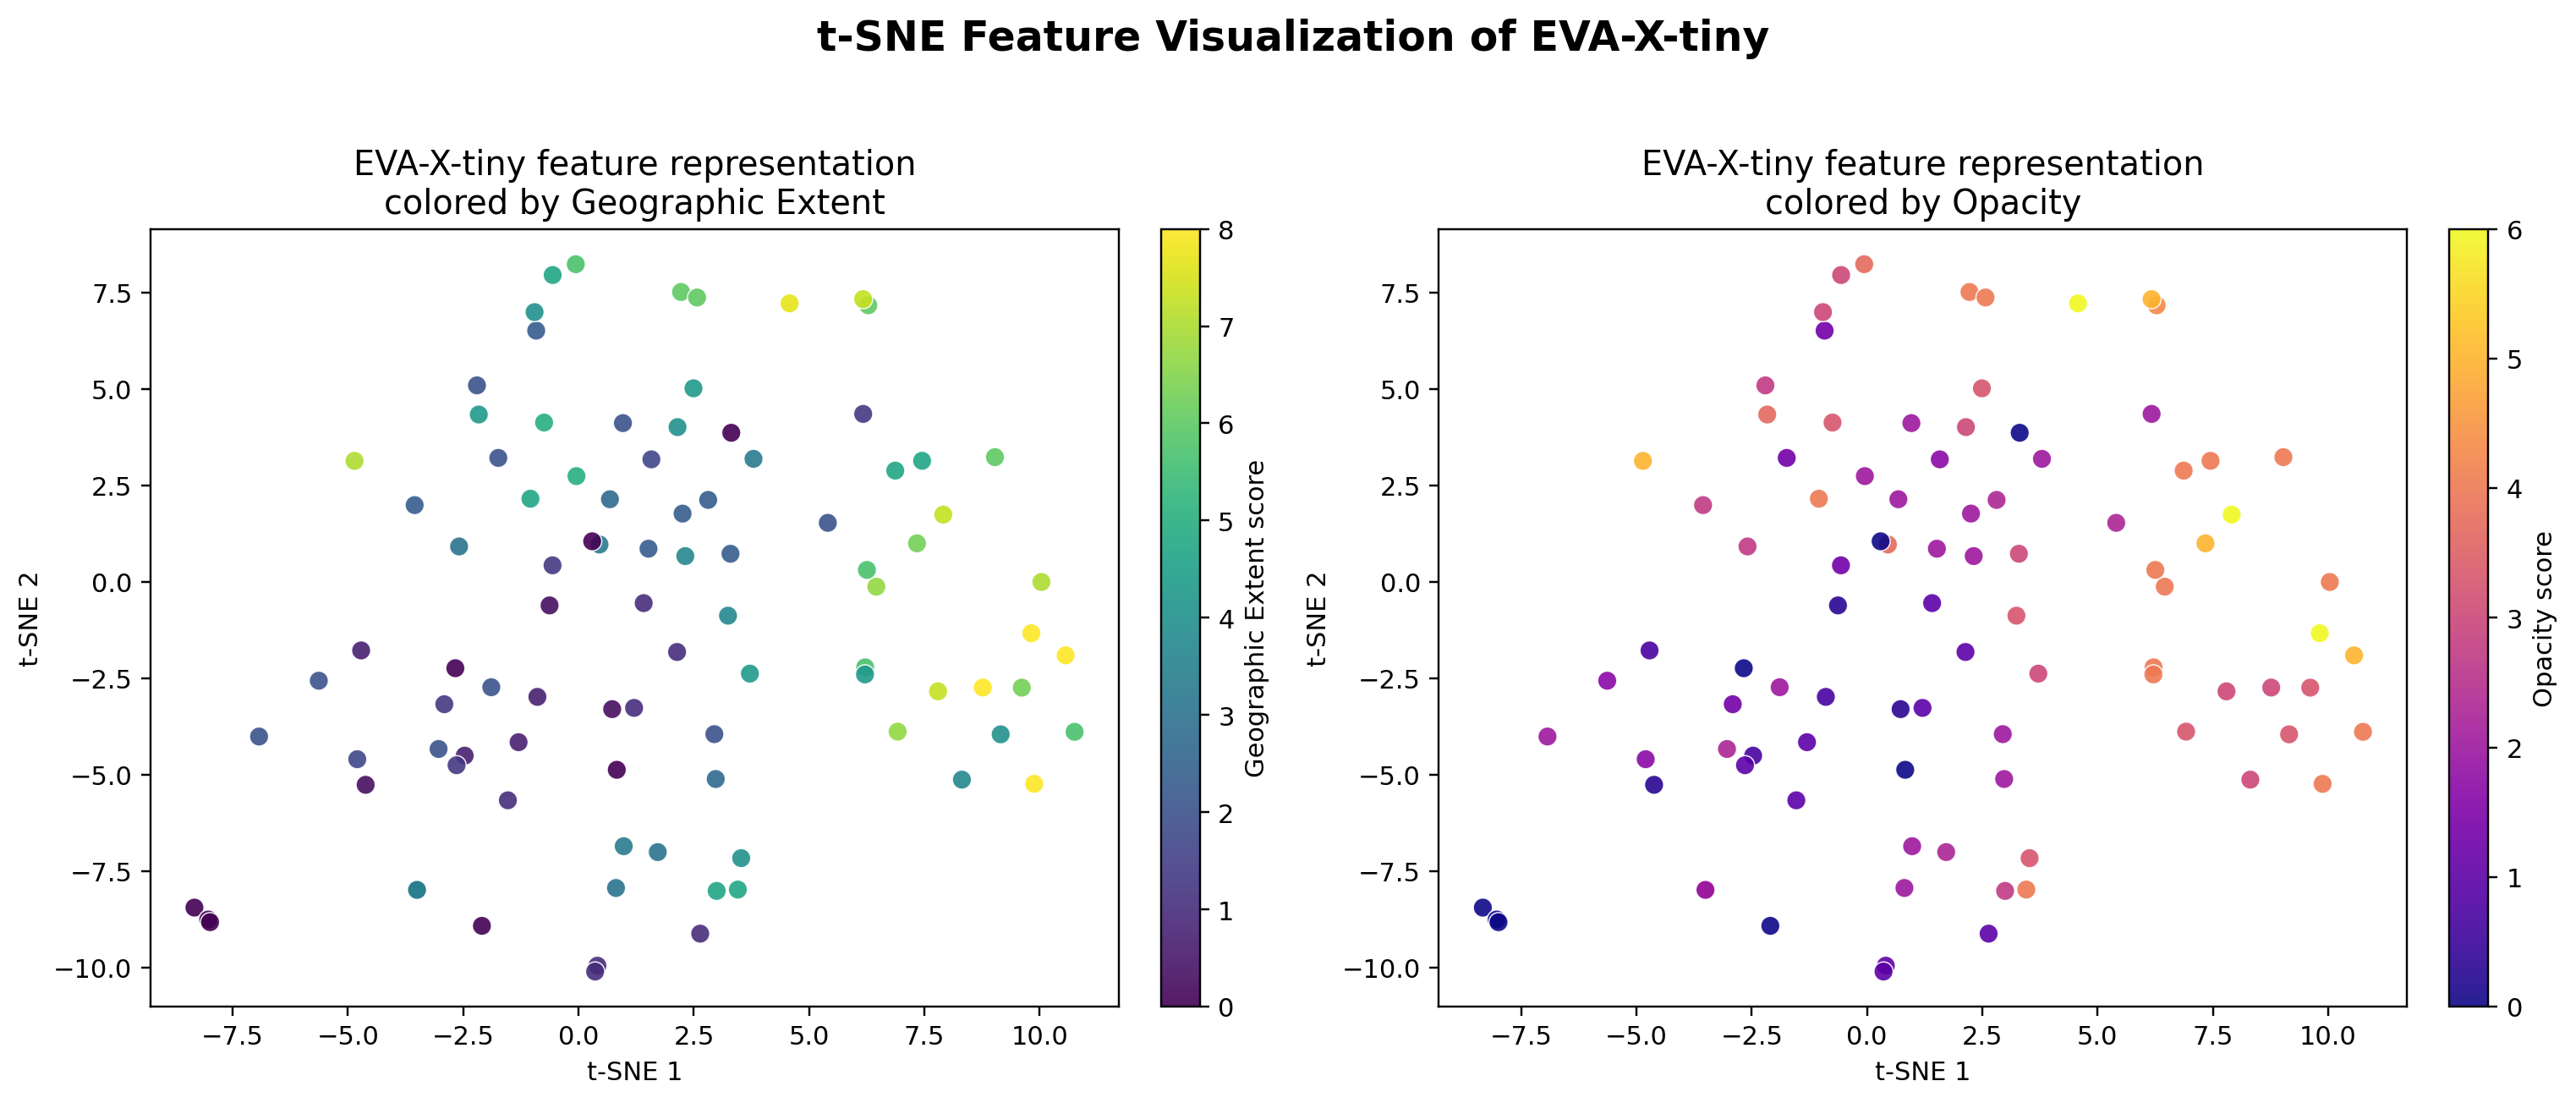

Saved PNG: /content/EVA_X_tSNE_Feature_Visualization.png
Saved PDF: /content/EVA_X_tSNE_Feature_Visualization.pdf


In [51]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# =========================================================
# File paths
# =========================================================
CACHE = Path("/content/duong-eva-x-results/eva_x_features.npz")
PRED = Path("/content/duong-eva-x-results/three_model_heldout_predictions.csv")

OUT_PNG = "/content/EVA_X_tSNE_Feature_Visualization.png"
OUT_PDF = "/content/EVA_X_tSNE_Feature_Visualization.pdf"
OUT_CSV = "/content/EVA_X_tSNE_coordinates.csv"

# =========================================================
# Safety checks
# =========================================================
if not CACHE.exists():
    raise FileNotFoundError(f"Missing EVA feature file: {CACHE}")

if not PRED.exists():
    raise FileNotFoundError(f"Missing predictions file: {PRED}")

# =========================================================
# Load EVA-X features
# =========================================================
with np.load(CACHE, allow_pickle=False) as f:
    if "features" not in f:
        raise KeyError("eva_x_features.npz must contain key 'features'")
    X = f["features"]

print("EVA feature shape:", X.shape)

# =========================================================
# Load labels from predictions file
# We use row_index to align labels with the feature rows.
# =========================================================
pred = pd.read_csv(PRED)

# Geographic Extent labels
geo = (
    pred[pred["target"] == "Geographic Extent"][["row_index", "filename", "patientid", "y_true"]]
    .drop_duplicates()
    .rename(columns={"y_true": "geographic_extent"})
)

# Opacity labels
opa = (
    pred[pred["target"] == "Opacity"][["row_index", "y_true"]]
    .drop_duplicates()
    .rename(columns={"y_true": "opacity"})
)

labels = geo.merge(opa, on="row_index", how="inner").sort_values("row_index").reset_index(drop=True)

print("Label table shape:", labels.shape)
print(labels.head())

# =========================================================
# Alignment checks
# =========================================================
if X.shape[0] != labels.shape[0]:
    raise ValueError(
        f"Feature rows ({X.shape[0]}) != label rows ({labels.shape[0]}). "
        "Please check row alignment."
    )

expected_index = np.arange(X.shape[0])
if not np.array_equal(labels["row_index"].to_numpy(), expected_index):
    raise ValueError(
        "row_index is not in 0..N-1 order. "
        "Please verify that the feature cache matches the prediction file."
    )

# =========================================================
# Standardize + t-SNE
# =========================================================
X_scaled = StandardScaler().fit_transform(X)

tsne = TSNE(
    n_components=2,
    perplexity=20,
    init="pca",
    learning_rate="auto",
    random_state=42
)

embedding = tsne.fit_transform(X_scaled)

labels["tsne_1"] = embedding[:, 0]
labels["tsne_2"] = embedding[:, 1]

labels.to_csv(OUT_CSV, index=False)
print(f"Saved coordinates to: {OUT_CSV}")

# =========================================================
# Plot
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=220)

# ----- Panel 1: Geographic Extent -----
sc1 = axes[0].scatter(
    labels["tsne_1"],
    labels["tsne_2"],
    c=labels["geographic_extent"],
    cmap="viridis",
    s=55,
    alpha=0.9,
    edgecolors="white",
    linewidths=0.5
)
axes[0].set_title("EVA-X-tiny feature representation\ncolored by Geographic Extent", fontsize=13)
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
cbar1 = plt.colorbar(sc1, ax=axes[0], fraction=0.046, pad=0.04)
cbar1.set_label("Geographic Extent score")

# ----- Panel 2: Opacity -----
sc2 = axes[1].scatter(
    labels["tsne_1"],
    labels["tsne_2"],
    c=labels["opacity"],
    cmap="plasma",
    s=55,
    alpha=0.9,
    edgecolors="white",
    linewidths=0.5
)
axes[1].set_title("EVA-X-tiny feature representation\ncolored by Opacity", fontsize=13)
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
cbar2 = plt.colorbar(sc2, ax=axes[1], fraction=0.046, pad=0.04)
cbar2.set_label("Opacity score")

fig.suptitle("t-SNE Feature Visualization of EVA-X-tiny", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(OUT_PNG, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print(f"Saved PNG: {OUT_PNG}")
print(f"Saved PDF: {OUT_PDF}")

In [52]:
from google.colab import files

files.download("/content/EVA_X_tSNE_Feature_Visualization.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
!find /content -name "eva_x_features.npz"

/content/duong-eva-x-results/eva_x_features.npz


In [55]:
from pathlib import Path
import pandas as pd
import numpy as np

# 原 EVA-X 实验保存的、有序样本信息
manifest_path = Path(
    "/content/duong-eva-x-results/ordered_sample_manifest.csv"
)

assert manifest_path.exists(), (
    f"Missing file: {manifest_path}"
)

# 恢复实验使用的 metadata
metadata = pd.read_csv(manifest_path)

# 验证数据维度
assert metadata.shape[0] == 94
assert eva_features.shape == (94, 192)
assert {"filename", "patientid"}.issubset(metadata.columns)

print("Metadata shape:", metadata.shape)
print("EVA features shape:", eva_features.shape)
print("Data alignment restored!")

Metadata shape: (94, 32)
EVA features shape: (94, 192)
Data alignment restored!


EVA feature shape: (94, 192)
Metadata shape: (94, 32)
Input image directory: /content/drive/MyDrive/duong-data/images
Alignment checks passed.

Patient-level split
Train images: 47
Test images: 47
Patient overlap: 0

Geographic Extent 
Best alpha: {'ridge__alpha': 100.0}

Opacity 
Best alpha: {'ridge__alpha': 100.0}
Geographic Extent: maximum prediction difference = 0.00000000
Opacity: maximum prediction difference = 0.00000000

Prediction verification passed.

Selected cases
           target                case_type  row_index                              filename  patientid  expert_score  predicted_score  absolute_error
Geographic Extent Representative low-error         72          covid-19-pneumonia-30-PA.jpg         93           3.0         3.071590        0.071590
Geographic Extent Representative low-error         83             covid-19-pneumonia-28.png         99           5.7         5.411654        0.288346
          Opacity Representative low-error          9 nCoV-radiol.202

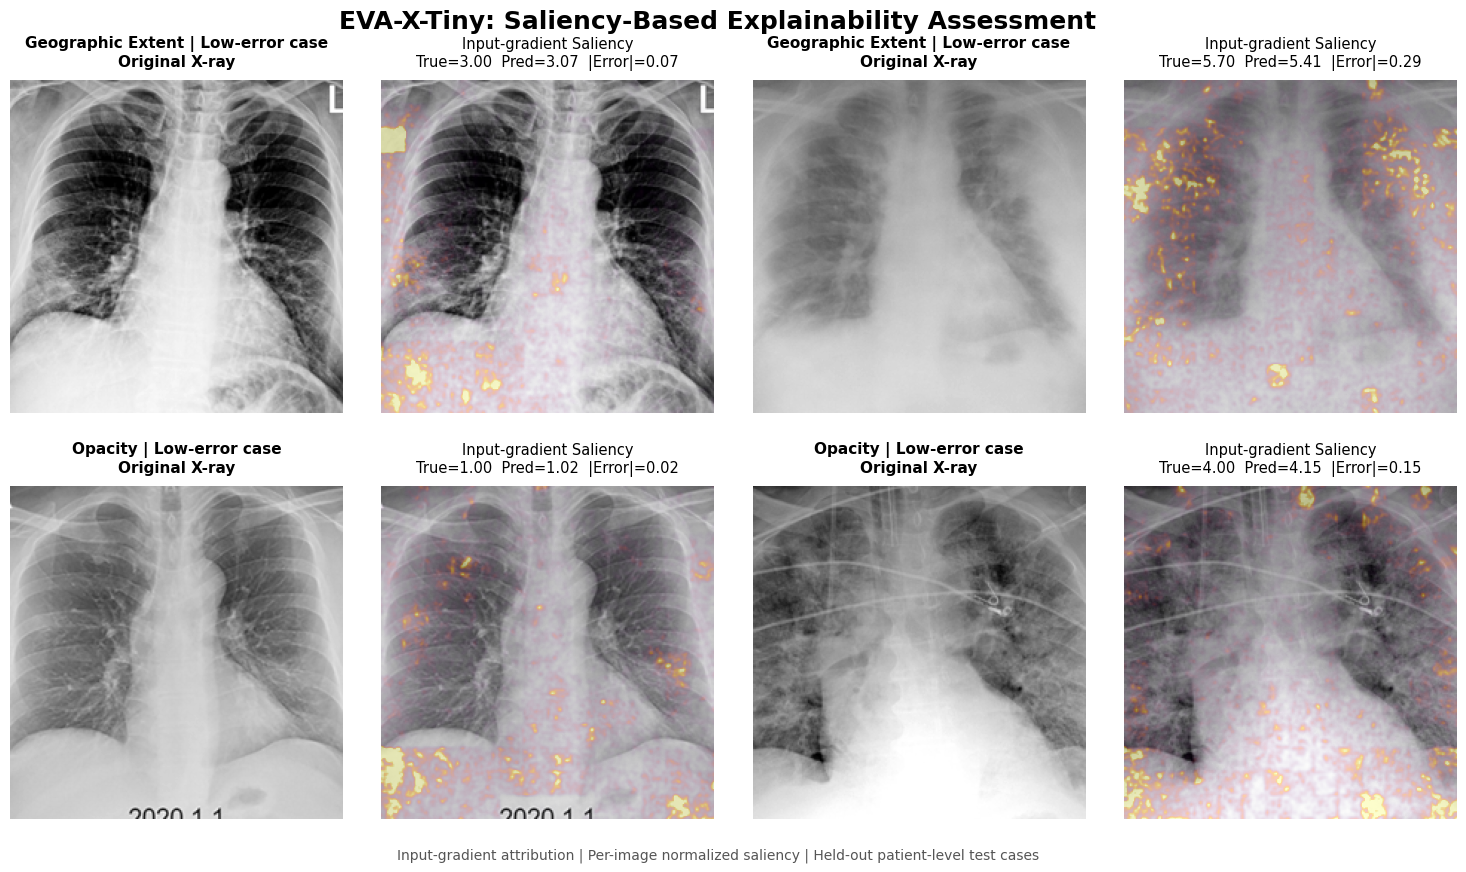


Files saved:
/content/duong-eva-x-results/saliency_figures/EVA_X_Saliency_Selected.pdf
/content/duong-eva-x-results/saliency_figures/EVA_X_Saliency_Selected.png
/content/duong-eva-x-results/saliency_figures/EVA_X_Selected_Cases.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
# ============================================================
# EVA-X-Tiny | Saliency-Based Explainability Assessment
#
# Real pretrained EVA-X + fitted Ridge regression
# Representative held-out cases
# PDF + PNG + case selection CSV
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import gaussian_filter

from sklearn.preprocessing import StandardScaler

from eva_x_methods import evaluation_transform
from resnet18_methods import ALPHAS, fit_nested_ridge
from critical_methods import exact_splits, TARGETS


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/content/duong-eva-x-results")
OUTPUT_DIR = ROOT / "saliency_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# "four_good": Four low-error cases
# "balanced": Three low-error cases + one high-error case
SELECTION_MODE = "four_good"

SEED = 0

# Prefer nonzero expert scores
MIN_TRUE_SCORE = 0.5

# Overlay visualization parameters
HEATMAP_ALPHA = 0.55
HEATMAP_POWER = 1.2
HEATMAP_PERCENTILE = 99

OUTPUT_PDF = OUTPUT_DIR / "EVA_X_Saliency_Selected.pdf"
OUTPUT_PNG = OUTPUT_DIR / "EVA_X_Saliency_Selected.png"
OUTPUT_CSV = OUTPUT_DIR / "EVA_X_Selected_Cases.csv"

MODEL_NAME = "EVA-X-Tiny + Ridge"

TARGET_NAMES = [
    "Geographic Extent",
    "Opacity"
]


# ============================================================
# 2. VALIDATE EXISTING VARIABLES
# ============================================================

required = [
    "eva",
    "eva_features",
    "metadata",
    "IMAGE_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
        + ". Run the original EVA-X notebook first."
    )

assert eva_features.shape == (94, 192), (
    f"Unexpected EVA features: {eva_features.shape}"
)

# Restore the original ordered metadata if necessary.
if len(metadata) != 94:

    manifest = ROOT / "ordered_sample_manifest.csv"

    if not manifest.exists():
        raise FileNotFoundError(
            "Metadata has the wrong number of rows, and "
            f"the ordered manifest is missing: {manifest}"
        )

    metadata = pd.read_csv(manifest)

assert len(metadata) == 94

assert {"filename", "patientid"}.issubset(
    metadata.columns
)

IMAGE_DIR = Path(IMAGE_DIR)

assert IMAGE_DIR.is_dir()

# Load saved predictions
pred_path = ROOT / "three_model_heldout_predictions.csv"

if pred_path.exists():
    saved_predictions = pd.read_csv(pred_path)
elif "predictions" in globals():
    saved_predictions = predictions.copy()
else:
    raise FileNotFoundError(
        "Cannot find held-out predictions."
    )

# Check sample identity if an ordered manifest is available
manifest_path = ROOT / "ordered_sample_manifest.csv"

if manifest_path.exists():
    ordered_manifest = pd.read_csv(manifest_path)

    assert ordered_manifest.filename.astype(str).tolist() == (
        metadata.filename.astype(str).tolist()
    ), "Metadata filename order mismatch."

# Basic prediction-to-metadata alignment
check = saved_predictions[
    saved_predictions.model == MODEL_NAME
].copy()

for _, rec in check.drop_duplicates(
    ["row_index", "filename"]
).iterrows():

    assert str(metadata.iloc[int(rec.row_index)].filename) == (
        str(rec.filename)
    ), "Feature and prediction image alignment mismatch."

print("EVA feature shape:", eva_features.shape)
print("Metadata shape:", metadata.shape)
print("Input image directory:", IMAGE_DIR)
print("Alignment checks passed.")


# ============================================================
# 3. RESTORE PATIENT-LEVEL TRAIN / TEST SPLIT
# ============================================================

split = next(
    (
        (tr, te)
        for seed, tr, te in exact_splits(metadata)
        if seed == SEED
    ),
    None
)

if split is None:
    raise RuntimeError("Requested seed not found.")

train_idx, test_idx = split

train_patients = set(
    metadata.iloc[train_idx].patientid
)

test_patients = set(
    metadata.iloc[test_idx].patientid
)

assert train_patients.isdisjoint(test_patients)

print("\nPatient-level split")
print("Train images:", len(train_idx))
print("Test images:", len(test_idx))
print("Patient overlap:", len(
    train_patients.intersection(test_patients)
))


# ============================================================
# 4. REFIT RIDGE REGRESSION HEADS
# ============================================================

regressors = {}

for target, label_column in TARGETS.items():

    y = metadata[label_column].to_numpy(float)

    fitted, folds, elapsed = fit_nested_ridge(
        eva_features[train_idx],
        y[train_idx],
        metadata.iloc[train_idx].patientid.to_numpy(),
        False,
        ALPHAS
    )

    estimator = fitted.best_estimator_

    scaler = next(
        (
            step
            for _, step in estimator.steps
            if isinstance(step, StandardScaler)
        ),
        None
    )

    ridge = next(
        (
            step
            for _, step in estimator.steps
            if hasattr(step, "coef_")
            and hasattr(step, "intercept_")
        ),
        None
    )

    if scaler is None or ridge is None:
        raise RuntimeError(
            f"Could not identify Ridge pipeline for {target}"
        )

    regressors[target] = {
        "fitted": fitted,
        "scaler": scaler,
        "ridge": ridge
    }

    print(
        f"\n{target}",
        "\nBest alpha:", fitted.best_params_
    )


# ============================================================
# 5. VERIFY SAVED PREDICTIONS
# ============================================================

saved = saved_predictions[
    (saved_predictions.model == MODEL_NAME)
    & (saved_predictions.seed == SEED)
].copy()

for target in TARGET_NAMES:

    fitted = regressors[target]["fitted"]

    part = saved[
        saved.target == target
    ].set_index("row_index")

    if not set(test_idx).issubset(set(part.index)):
        raise ValueError(
            f"Saved test indices do not match for {target}"
        )

    regenerated = fitted.predict(
        eva_features[test_idx]
    )

    stored = part.loc[
        test_idx, "y_pred"
    ].to_numpy(float)

    max_difference = np.max(
        np.abs(regenerated - stored)
    )

    print(
        f"{target}: maximum prediction difference = "
        f"{max_difference:.8f}"
    )

    if max_difference > 1e-4:
        raise ValueError(
            "Refitted model differs from original predictions."
        )

print("\nPrediction verification passed.")


# ============================================================
# 6. SELECT REPRESENTATIVE CASES
# ============================================================

selected = {}
used_patients = set()

def choose_case(part, used_patients, high_error=False,
                previous_scores=None):

    previous_scores = previous_scores or []

    candidates = part[
        ~part.patientid.isin(used_patients)
    ].copy()

    if candidates.empty:
        raise RuntimeError(
            "Not enough distinct held-out patients."
        )

    # Prefer cases with nonzero expert scores
    positive = candidates[
        candidates.y_true >= MIN_TRUE_SCORE
    ]

    if len(positive) > 0:
        candidates = positive

    # Rank by prediction accuracy
    candidates = candidates.sort_values(
        ["absolute_error", "row_index"],
        ascending=[not high_error, True]
    )

    if high_error or not previous_scores:
        return candidates.iloc[0]

    # For the second low-error case, prefer a different
    # severity level among reasonably accurate candidates.
    pool = candidates.head(min(15, len(candidates))).copy()

    pool["severity_difference"] = pool.y_true.apply(
        lambda value: min(
            abs(value - p) for p in previous_scores
        )
    )

    pool = pool.sort_values(
        ["severity_difference", "absolute_error"],
        ascending=[False, True]
    )

    return pool.iloc[0]


for target in TARGET_NAMES:

    part = saved[
        saved.target == target
    ].copy()

    part["absolute_error"] = (
        part.y_true - part.y_pred
    ).abs()

    chosen = []

    # First case: low-error
    case1 = choose_case(
        part,
        used_patients
    )

    chosen.append(case1)
    used_patients.add(case1.patientid)

    # Second case: low-error or high-error
    high_error = (
        SELECTION_MODE == "balanced"
        and target == "Opacity"
    )

    case2 = choose_case(
        part,
        used_patients,
        high_error=high_error,
        previous_scores=[float(case1.y_true)]
    )

    chosen.append(case2)
    used_patients.add(case2.patientid)

    selected[target] = chosen


print("\nSelected cases")
records = []

for target in TARGET_NAMES:

    for j, case in enumerate(selected[target]):

        tag = "Representative low-error"

        if (
            SELECTION_MODE == "balanced"
            and target == "Opacity"
            and j == 1
        ):
            tag = "Representative high-error"

        records.append({
            "target": target,
            "case_type": tag,
            "row_index": int(case.row_index),
            "filename": case.filename,
            "patientid": case.patientid,
            "expert_score": case.y_true,
            "predicted_score": case.y_pred,
            "absolute_error": abs(
                case.y_true - case.y_pred
            )
        })

selection_df = pd.DataFrame(records)

print(selection_df.to_string(index=False))

selection_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ============================================================
# 7. LOAD FROZEN EVA-X MODEL
# ============================================================

assert not eva.training
assert not any(
    p.requires_grad for p in eva.parameters()
)

model = eva.cpu().eval()
model.requires_grad_(False)

transform = evaluation_transform()

torch.set_num_threads(2)


# ============================================================
# 8. COMPUTE INPUT-GRADIENT SALIENCY
# ============================================================

def compute_saliency(target, case):

    path = IMAGE_DIR / str(case.filename)

    if not path.exists():
        raise FileNotFoundError(path)

    image = Image.open(path).convert("RGB")

    x = transform(image).unsqueeze(0)
    x = x.requires_grad_(True)

    with torch.enable_grad():

        features = model.forward_head(
            model.forward_features(x),
            pre_logits=True
        )

        assert features.shape == (1, 192)

        scaler = regressors[target]["scaler"]
        ridge = regressors[target]["ridge"]

        # Convert StandardScaler + Ridge to an
        # equivalent linear function of EVA features
        coef = np.asarray(
            ridge.coef_
        ).reshape(-1)

        scale = np.asarray(
            scaler.scale_
        )

        mean = np.asarray(
            scaler.mean_
        )

        weights_np = coef / scale

        intercept_np = (
            float(ridge.intercept_)
            - np.dot(coef, mean / scale)
        )

        weights = torch.as_tensor(
            weights_np,
            dtype=features.dtype,
            device=features.device
        )

        prediction = (
            features @ weights + intercept_np
        ).squeeze()

        gradient = torch.autograd.grad(
            prediction,
            x,
            retain_graph=False,
            create_graph=False
        )[0]

    predicted = float(
        prediction.detach().cpu()
    )

    # Verify the actual model output
    if abs(predicted - float(case.y_pred)) > 1e-3:
        raise RuntimeError(
            "Saliency prediction differs from saved prediction."
        )

    gradient = (
        gradient[0]
        .detach()
        .abs()
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    # Recover grayscale image from normalized input
    gray = (
        x.detach()[0]
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    gray = np.clip(
        gray * 0.28509309 + 0.49185243,
        0,
        1
    )

    # Smooth gradients for visualization
    saliency = gaussian_filter(
        gradient,
        sigma=1.0
    )

    # Per-image percentile normalization
    denominator = np.percentile(
        saliency,
        HEATMAP_PERCENTILE
    )

    saliency = np.clip(
        saliency / max(denominator, 1e-12),
        0,
        1
    )

    return gray, saliency, predicted


# ============================================================
# 9. GENERATE PUBLICATION-STYLE FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    2,
    4,
    figsize=(15.5, 8.8),
    constrained_layout=False
)

fig.patch.set_facecolor("white")

for i, target in enumerate(TARGET_NAMES):

    for j, case in enumerate(selected[target]):

        gray, heat, predicted = compute_saliency(
            target,
            case
        )

        a = axes[i, 2*j]
        b = axes[i, 2*j+1]

        # Original X-ray
        a.imshow(
            gray,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        # Saliency overlay
        b.imshow(
            gray,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        alpha = np.clip(
            heat**HEATMAP_POWER * HEATMAP_ALPHA,
            0,
            HEATMAP_ALPHA
        )

        b.imshow(
            heat,
            cmap="inferno",
            vmin=0,
            vmax=1,
            alpha=alpha
        )

        error = abs(
            float(case.y_true) - predicted
        )

        if (
            SELECTION_MODE == "balanced"
            and target == "Opacity"
            and j == 1
        ):
            case_title = "High-error case"
        else:
            case_title = "Low-error case"

        a.set_title(
            f"{target} | {case_title}\n"
            f"Original X-ray",
            fontsize=11,
            fontweight="bold",
            pad=10
        )

        b.set_title(
            "Input-gradient Saliency\n"
            f"True={case.y_true:.2f}  "
            f"Pred={predicted:.2f}  "
            f"|Error|={error:.2f}",
            fontsize=10.5,
            pad=10
        )

        for axis in [a, b]:
            axis.axis("off")

        print(
            f"{target} | {case_title} | "
            f"Patient {case.patientid} | "
            f"Error {error:.3f}"
        )


fig.suptitle(
    "EVA-X-Tiny: Saliency-Based Explainability Assessment",
    fontsize=18,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.035,
    right=0.985,
    top=0.91,
    bottom=0.07,
    wspace=0.035,
    hspace=0.22
)

fig.text(
    0.5,
    0.025,
    "Input-gradient attribution | "
    "Per-image normalized saliency | "
    "Held-out patient-level test cases",
    ha="center",
    fontsize=10,
    color="#555555"
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFiles saved:")
print(OUTPUT_PDF)
print(OUTPUT_PNG)
print(OUTPUT_CSV)


# ============================================================
# 10. DOWNLOAD TO LOCAL COMPUTER
# ============================================================

from google.colab import files

files.download(str(OUTPUT_PDF))

EVA feature shape: (94, 192)
Metadata shape: (94, 32)
Input image directory: /content/drive/MyDrive/duong-data/images
Alignment checks passed.

Patient-level split
Train images: 47
Test images: 47
Patient overlap: 0

Geographic Extent 
Best alpha: {'ridge__alpha': 100.0}

Opacity 
Best alpha: {'ridge__alpha': 100.0}
Geographic Extent: maximum prediction difference = 0.00000000
Opacity: maximum prediction difference = 0.00000000

Prediction verification passed.

Selected cases
           target                 case_type  row_index                                  filename  patientid  expert_score  predicted_score  absolute_error
Geographic Extent  Representative low-error         72              covid-19-pneumonia-30-PA.jpg         93           3.0         3.071590        0.071590
Geographic Extent  Representative low-error         83                 covid-19-pneumonia-28.png         99           5.7         5.411654        0.288346
          Opacity  Representative low-error          9

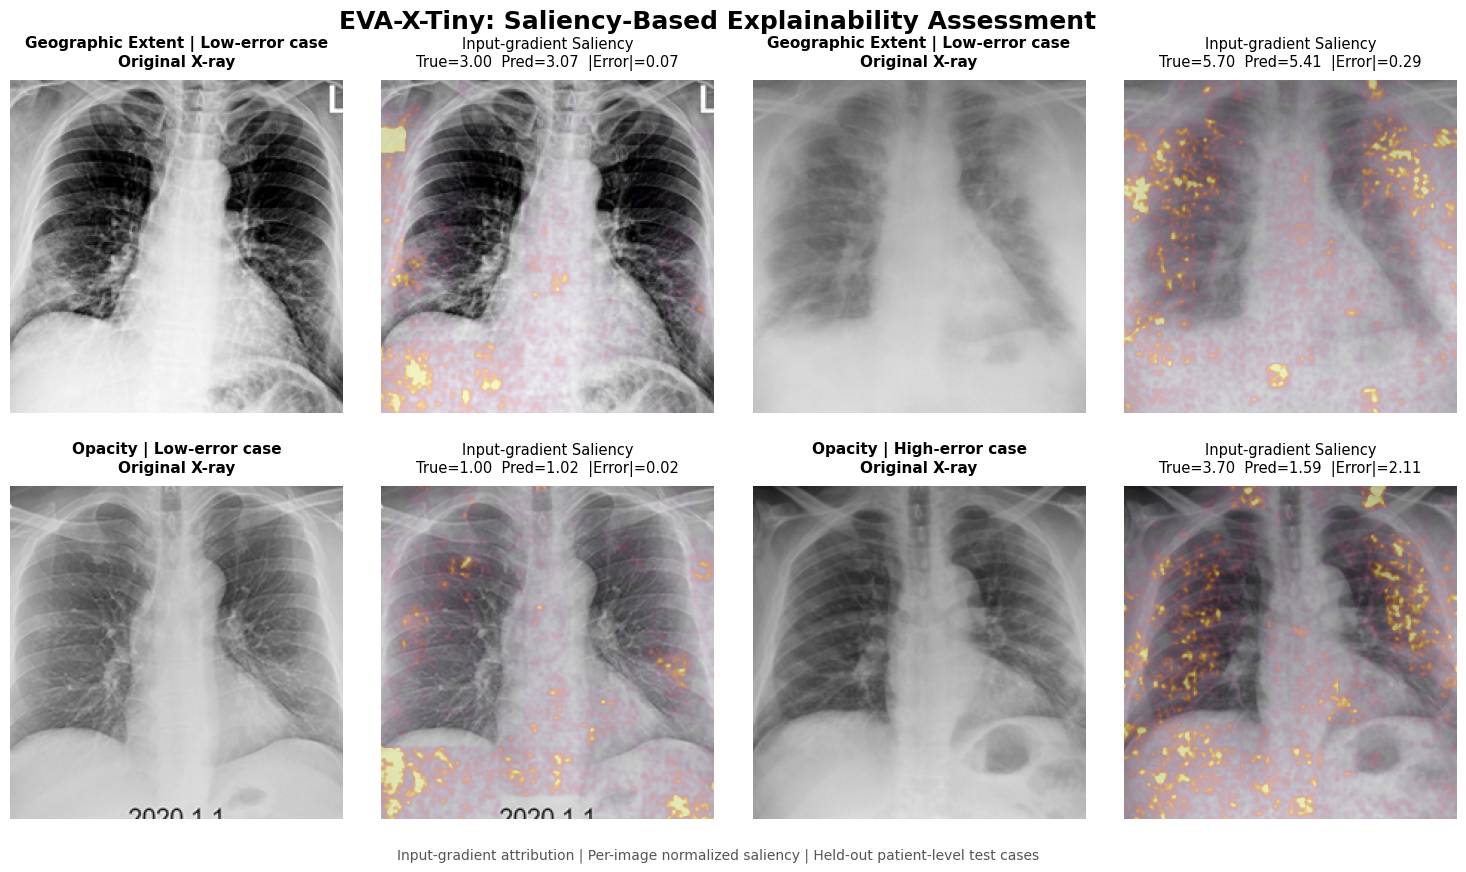


Files saved:
/content/duong-eva-x-results/saliency_figures/EVA_X_Saliency_Selected.pdf
/content/duong-eva-x-results/saliency_figures/EVA_X_Saliency_Selected.png
/content/duong-eva-x-results/saliency_figures/EVA_X_Selected_Cases.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
# ============================================================
# EVA-X-Tiny | Saliency-Based Explainability Assessment
#
# Real pretrained EVA-X + fitted Ridge regression
# Representative held-out cases
# PDF + PNG + case selection CSV
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import gaussian_filter

from sklearn.preprocessing import StandardScaler

from eva_x_methods import evaluation_transform
from resnet18_methods import ALPHAS, fit_nested_ridge
from critical_methods import exact_splits, TARGETS


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/content/duong-eva-x-results")
OUTPUT_DIR = ROOT / "saliency_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# "four_good": Four low-error cases
# "balanced": Three low-error cases + one high-error case
SELECTION_MODE = "balanced"

SEED = 0

# Prefer nonzero expert scores
MIN_TRUE_SCORE = 0.5

# Overlay visualization parameters
HEATMAP_ALPHA = 0.55
HEATMAP_POWER = 1.2
HEATMAP_PERCENTILE = 99

OUTPUT_PDF = OUTPUT_DIR / "EVA_X_Saliency_Selected.pdf"
OUTPUT_PNG = OUTPUT_DIR / "EVA_X_Saliency_Selected.png"
OUTPUT_CSV = OUTPUT_DIR / "EVA_X_Selected_Cases.csv"

MODEL_NAME = "EVA-X-Tiny + Ridge"

TARGET_NAMES = [
    "Geographic Extent",
    "Opacity"
]


# ============================================================
# 2. VALIDATE EXISTING VARIABLES
# ============================================================

required = [
    "eva",
    "eva_features",
    "metadata",
    "IMAGE_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
        + ". Run the original EVA-X notebook first."
    )

assert eva_features.shape == (94, 192), (
    f"Unexpected EVA features: {eva_features.shape}"
)

# Restore the original ordered metadata if necessary.
if len(metadata) != 94:

    manifest = ROOT / "ordered_sample_manifest.csv"

    if not manifest.exists():
        raise FileNotFoundError(
            "Metadata has the wrong number of rows, and "
            f"the ordered manifest is missing: {manifest}"
        )

    metadata = pd.read_csv(manifest)

assert len(metadata) == 94

assert {"filename", "patientid"}.issubset(
    metadata.columns
)

IMAGE_DIR = Path(IMAGE_DIR)

assert IMAGE_DIR.is_dir()

# Load saved predictions
pred_path = ROOT / "three_model_heldout_predictions.csv"

if pred_path.exists():
    saved_predictions = pd.read_csv(pred_path)
elif "predictions" in globals():
    saved_predictions = predictions.copy()
else:
    raise FileNotFoundError(
        "Cannot find held-out predictions."
    )

# Check sample identity if an ordered manifest is available
manifest_path = ROOT / "ordered_sample_manifest.csv"

if manifest_path.exists():
    ordered_manifest = pd.read_csv(manifest_path)

    assert ordered_manifest.filename.astype(str).tolist() == (
        metadata.filename.astype(str).tolist()
    ), "Metadata filename order mismatch."

# Basic prediction-to-metadata alignment
check = saved_predictions[
    saved_predictions.model == MODEL_NAME
].copy()

for _, rec in check.drop_duplicates(
    ["row_index", "filename"]
).iterrows():

    assert str(metadata.iloc[int(rec.row_index)].filename) == (
        str(rec.filename)
    ), "Feature and prediction image alignment mismatch."

print("EVA feature shape:", eva_features.shape)
print("Metadata shape:", metadata.shape)
print("Input image directory:", IMAGE_DIR)
print("Alignment checks passed.")


# ============================================================
# 3. RESTORE PATIENT-LEVEL TRAIN / TEST SPLIT
# ============================================================

split = next(
    (
        (tr, te)
        for seed, tr, te in exact_splits(metadata)
        if seed == SEED
    ),
    None
)

if split is None:
    raise RuntimeError("Requested seed not found.")

train_idx, test_idx = split

train_patients = set(
    metadata.iloc[train_idx].patientid
)

test_patients = set(
    metadata.iloc[test_idx].patientid
)

assert train_patients.isdisjoint(test_patients)

print("\nPatient-level split")
print("Train images:", len(train_idx))
print("Test images:", len(test_idx))
print("Patient overlap:", len(
    train_patients.intersection(test_patients)
))


# ============================================================
# 4. REFIT RIDGE REGRESSION HEADS
# ============================================================

regressors = {}

for target, label_column in TARGETS.items():

    y = metadata[label_column].to_numpy(float)

    fitted, folds, elapsed = fit_nested_ridge(
        eva_features[train_idx],
        y[train_idx],
        metadata.iloc[train_idx].patientid.to_numpy(),
        False,
        ALPHAS
    )

    estimator = fitted.best_estimator_

    scaler = next(
        (
            step
            for _, step in estimator.steps
            if isinstance(step, StandardScaler)
        ),
        None
    )

    ridge = next(
        (
            step
            for _, step in estimator.steps
            if hasattr(step, "coef_")
            and hasattr(step, "intercept_")
        ),
        None
    )

    if scaler is None or ridge is None:
        raise RuntimeError(
            f"Could not identify Ridge pipeline for {target}"
        )

    regressors[target] = {
        "fitted": fitted,
        "scaler": scaler,
        "ridge": ridge
    }

    print(
        f"\n{target}",
        "\nBest alpha:", fitted.best_params_
    )


# ============================================================
# 5. VERIFY SAVED PREDICTIONS
# ============================================================

saved = saved_predictions[
    (saved_predictions.model == MODEL_NAME)
    & (saved_predictions.seed == SEED)
].copy()

for target in TARGET_NAMES:

    fitted = regressors[target]["fitted"]

    part = saved[
        saved.target == target
    ].set_index("row_index")

    if not set(test_idx).issubset(set(part.index)):
        raise ValueError(
            f"Saved test indices do not match for {target}"
        )

    regenerated = fitted.predict(
        eva_features[test_idx]
    )

    stored = part.loc[
        test_idx, "y_pred"
    ].to_numpy(float)

    max_difference = np.max(
        np.abs(regenerated - stored)
    )

    print(
        f"{target}: maximum prediction difference = "
        f"{max_difference:.8f}"
    )

    if max_difference > 1e-4:
        raise ValueError(
            "Refitted model differs from original predictions."
        )

print("\nPrediction verification passed.")


# ============================================================
# 6. SELECT REPRESENTATIVE CASES
# ============================================================

selected = {}
used_patients = set()

def choose_case(part, used_patients, high_error=False,
                previous_scores=None):

    previous_scores = previous_scores or []

    candidates = part[
        ~part.patientid.isin(used_patients)
    ].copy()

    if candidates.empty:
        raise RuntimeError(
            "Not enough distinct held-out patients."
        )

    # Prefer cases with nonzero expert scores
    positive = candidates[
        candidates.y_true >= MIN_TRUE_SCORE
    ]

    if len(positive) > 0:
        candidates = positive

    # Rank by prediction accuracy
    candidates = candidates.sort_values(
        ["absolute_error", "row_index"],
        ascending=[not high_error, True]
    )

    if high_error or not previous_scores:
        return candidates.iloc[0]

    # For the second low-error case, prefer a different
    # severity level among reasonably accurate candidates.
    pool = candidates.head(min(15, len(candidates))).copy()

    pool["severity_difference"] = pool.y_true.apply(
        lambda value: min(
            abs(value - p) for p in previous_scores
        )
    )

    pool = pool.sort_values(
        ["severity_difference", "absolute_error"],
        ascending=[False, True]
    )

    return pool.iloc[0]


for target in TARGET_NAMES:

    part = saved[
        saved.target == target
    ].copy()

    part["absolute_error"] = (
        part.y_true - part.y_pred
    ).abs()

    chosen = []

    # First case: low-error
    case1 = choose_case(
        part,
        used_patients
    )

    chosen.append(case1)
    used_patients.add(case1.patientid)

    # Second case: low-error or high-error
    high_error = (
        SELECTION_MODE == "balanced"
        and target == "Opacity"
    )

    case2 = choose_case(
        part,
        used_patients,
        high_error=high_error,
        previous_scores=[float(case1.y_true)]
    )

    chosen.append(case2)
    used_patients.add(case2.patientid)

    selected[target] = chosen


print("\nSelected cases")
records = []

for target in TARGET_NAMES:

    for j, case in enumerate(selected[target]):

        tag = "Representative low-error"

        if (
            SELECTION_MODE == "balanced"
            and target == "Opacity"
            and j == 1
        ):
            tag = "Representative high-error"

        records.append({
            "target": target,
            "case_type": tag,
            "row_index": int(case.row_index),
            "filename": case.filename,
            "patientid": case.patientid,
            "expert_score": case.y_true,
            "predicted_score": case.y_pred,
            "absolute_error": abs(
                case.y_true - case.y_pred
            )
        })

selection_df = pd.DataFrame(records)

print(selection_df.to_string(index=False))

selection_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ============================================================
# 7. LOAD FROZEN EVA-X MODEL
# ============================================================

assert not eva.training
assert not any(
    p.requires_grad for p in eva.parameters()
)

model = eva.cpu().eval()
model.requires_grad_(False)

transform = evaluation_transform()

torch.set_num_threads(2)


# ============================================================
# 8. COMPUTE INPUT-GRADIENT SALIENCY
# ============================================================

def compute_saliency(target, case):

    path = IMAGE_DIR / str(case.filename)

    if not path.exists():
        raise FileNotFoundError(path)

    image = Image.open(path).convert("RGB")

    x = transform(image).unsqueeze(0)
    x = x.requires_grad_(True)

    with torch.enable_grad():

        features = model.forward_head(
            model.forward_features(x),
            pre_logits=True
        )

        assert features.shape == (1, 192)

        scaler = regressors[target]["scaler"]
        ridge = regressors[target]["ridge"]

        # Convert StandardScaler + Ridge to an
        # equivalent linear function of EVA features
        coef = np.asarray(
            ridge.coef_
        ).reshape(-1)

        scale = np.asarray(
            scaler.scale_
        )

        mean = np.asarray(
            scaler.mean_
        )

        weights_np = coef / scale

        intercept_np = (
            float(ridge.intercept_)
            - np.dot(coef, mean / scale)
        )

        weights = torch.as_tensor(
            weights_np,
            dtype=features.dtype,
            device=features.device
        )

        prediction = (
            features @ weights + intercept_np
        ).squeeze()

        gradient = torch.autograd.grad(
            prediction,
            x,
            retain_graph=False,
            create_graph=False
        )[0]

    predicted = float(
        prediction.detach().cpu()
    )

    # Verify the actual model output
    if abs(predicted - float(case.y_pred)) > 1e-3:
        raise RuntimeError(
            "Saliency prediction differs from saved prediction."
        )

    gradient = (
        gradient[0]
        .detach()
        .abs()
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    # Recover grayscale image from normalized input
    gray = (
        x.detach()[0]
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    gray = np.clip(
        gray * 0.28509309 + 0.49185243,
        0,
        1
    )

    # Smooth gradients for visualization
    saliency = gaussian_filter(
        gradient,
        sigma=1.0
    )

    # Per-image percentile normalization
    denominator = np.percentile(
        saliency,
        HEATMAP_PERCENTILE
    )

    saliency = np.clip(
        saliency / max(denominator, 1e-12),
        0,
        1
    )

    return gray, saliency, predicted


# ============================================================
# 9. GENERATE PUBLICATION-STYLE FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    2,
    4,
    figsize=(15.5, 8.8),
    constrained_layout=False
)

fig.patch.set_facecolor("white")

for i, target in enumerate(TARGET_NAMES):

    for j, case in enumerate(selected[target]):

        gray, heat, predicted = compute_saliency(
            target,
            case
        )

        a = axes[i, 2*j]
        b = axes[i, 2*j+1]

        # Original X-ray
        a.imshow(
            gray,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        # Saliency overlay
        b.imshow(
            gray,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        alpha = np.clip(
            heat**HEATMAP_POWER * HEATMAP_ALPHA,
            0,
            HEATMAP_ALPHA
        )

        b.imshow(
            heat,
            cmap="inferno",
            vmin=0,
            vmax=1,
            alpha=alpha
        )

        error = abs(
            float(case.y_true) - predicted
        )

        if (
            SELECTION_MODE == "balanced"
            and target == "Opacity"
            and j == 1
        ):
            case_title = "High-error case"
        else:
            case_title = "Low-error case"

        a.set_title(
            f"{target} | {case_title}\n"
            f"Original X-ray",
            fontsize=11,
            fontweight="bold",
            pad=10
        )

        b.set_title(
            "Input-gradient Saliency\n"
            f"True={case.y_true:.2f}  "
            f"Pred={predicted:.2f}  "
            f"|Error|={error:.2f}",
            fontsize=10.5,
            pad=10
        )

        for axis in [a, b]:
            axis.axis("off")

        print(
            f"{target} | {case_title} | "
            f"Patient {case.patientid} | "
            f"Error {error:.3f}"
        )


fig.suptitle(
    "EVA-X-Tiny: Saliency-Based Explainability Assessment",
    fontsize=18,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.035,
    right=0.985,
    top=0.91,
    bottom=0.07,
    wspace=0.035,
    hspace=0.22
)

fig.text(
    0.5,
    0.025,
    "Input-gradient attribution | "
    "Per-image normalized saliency | "
    "Held-out patient-level test cases",
    ha="center",
    fontsize=10,
    color="#555555"
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFiles saved:")
print(OUTPUT_PDF)
print(OUTPUT_PNG)
print(OUTPUT_CSV)


# ============================================================
# 10. DOWNLOAD TO LOCAL COMPUTER
# ============================================================

from google.colab import files

files.download(str(OUTPUT_PDF))

In [54]:
print("EVA features shape:", eva_features.shape)
print("Metadata shape:", metadata.shape)
print("Metadata columns:", metadata.columns.tolist())
print(metadata.head())

EVA features shape: (94, 192)
Metadata shape: (360, 29)
Metadata columns: ['patientid', 'offset', 'sex', 'age', 'finding', 'survival', 'intubated', 'intubation_present', 'went_icu', 'needed_supplemental_O2', 'extubated', 'temperature', 'pO2_saturation', 'leukocyte_count', 'neutrophil_count', 'lymphocyte_count', 'view', 'modality', 'date', 'location', 'folder', 'filename', 'doi', 'url', 'license', 'clinical_notes', 'other_notes', 'Unnamed: 27', 'match_filename']
   patientid  offset sex   age   finding survival intubated  \
0          2     0.0   M  65.0  COVID-19        Y       NaN   
1          2     3.0   M  65.0  COVID-19        Y       NaN   
2          2     5.0   M  65.0  COVID-19        Y       NaN   
3          2     6.0   M  65.0  COVID-19        Y       NaN   
4          4     0.0   F  52.0  COVID-19      NaN       NaN   

  intubation_present went_icu needed_supplemental_O2  ...  \
0                NaN      NaN                    NaN  ...   
1                NaN      NaN    

In [59]:
from google.colab import files

files.download(
    "/content/duong-eva-x-results/eva_x_prediction_scatter.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
from google.colab import files

files.download(
    "/content/duong-eva-x-results/three_model_comparison.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>